In [1]:
from src.utils.data_cleaning import image_preprocessing, get_file_paths, move_file, extrac_vehicle_from_dir
from src.utils.logging_config import setup_logging
from src.utils.model import create_model, log_number_of_params
from src.train import (create_train_val_loader, 
                        evaluate_tm, 
                        train, create_subset_from_loader, 
                        create_cv_loaders, create_dataloader, 
                        # fit_temperature, extract_features,
                        calc_centroids_cov_inv,
                        mahalanobis_min_distance, train_vgg)

from src.utils.ood import extract_features, fit_mahalanobis, fit_temperature, fit_ood_thresholds, predict, calculate_ood_scores, load_checkpoint

#from src.predict import predict, load_checkpoint

from src.utils.display_images import ims_show, plot_confusion_matrices, plot_misclassified_images
import torch
import torch.nn as nn
import torchmetrics
from torch.utils.data import DataLoader, Subset
import numpy as np
from pathlib import Path
import torchvision.transforms.v2 as transforms
import matplotlib.pyplot as plt


In [2]:
setup_logging()
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cuda'

In [4]:
image_preprocessing()

In [ ]:
extrac_vehicle_from_dir()

--- Logging error ---
Traceback (most recent call last):
  File "C:\Anaconda\envs\torch-gpu\lib\logging\__init__.py", line 1100, in emit
    msg = self.format(record)
  File "C:\Anaconda\envs\torch-gpu\lib\logging\__init__.py", line 943, in format
    return fmt.format(record)
  File "C:\Anaconda\envs\torch-gpu\lib\logging\__init__.py", line 678, in format
    record.message = record.getMessage()
  File "C:\Anaconda\envs\torch-gpu\lib\logging\__init__.py", line 368, in getMessage
    msg = msg % self.args
TypeError: not all arguments converted during string formatting
Call stack:
  File "C:\Anaconda\envs\torch-gpu\lib\runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "C:\Anaconda\envs\torch-gpu\lib\runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "C:\Anaconda\envs\torch-gpu\lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Anaconda\envs\torch-gpu\lib\site-packages\tr

In [16]:
train_transform = transforms.Compose(
    [
        transforms.ToImage(),

        transforms.Resize(256),

        transforms.RandomResizedCrop(
            size=(224, 224),
            scale=(0.7, 1.0),
            ratio=(0.75, 1.33),
        ),

        transforms.RandomHorizontalFlip(p=0.5),

        transforms.ColorJitter(
            brightness=0.3,
            contrast=0.05,
        ),

        # Convert uint8 [0, 255] → float32 [0, 1]
        transforms.ToDtype(
            torch.float32,
            scale=True,
        ),

        # Blur
        transforms.RandomApply(
            [
                transforms.GaussianBlur(
                    kernel_size=5,
                    sigma=(0.1, 1.0),
                )
            ],
            p=0.15,
        ),

        # Gaussian noise
        transforms.RandomApply(
            [
                transforms.GaussianNoise(
                    mean=0.0,
                    sigma=0.03,
                )
            ],
            p=0.15,
        ),

        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        ),
    ]
)

valid_transform = transforms.Compose(
        [
            transforms.ToImage(),
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToDtype(torch.float32, scale=True),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
            ),
        ]
)

# train_loader, classes = create_dataloader(path="data/train", transformation=train_transform)
# train_loader2, _ = create_dataloader(path="data/cropped", transformation=train_transform)
# valid_loader, _ = create_dataloader(path="data/test", transformation=valid_transform, val=True)
# ood_loader, _ = create_dataloader(path='data/train-neysan', transformation=valid_transform, val=True)
test0, classes = create_dataloader(path='data/test-data/test0', transformation=valid_transform, val=True)
test1, _ = create_dataloader(path='data/test-data/test1', transformation=valid_transform, val=True)
test2, _ = create_dataloader(path='data/test-data/test2', transformation=valid_transform, val=True)
test3, _ = create_dataloader(path='data/test-data/test3', transformation=valid_transform, val=True)
test4, _ = create_dataloader(path='data/test-data/test4', transformation=valid_transform, val=True)
print(f"classes: {classes}")

classes: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']


In [ ]:
for classname in ["ambulance", "autobus", "kamyun", "kamyunet", "minibus", "savari", "taxi", "vanet"]:
    files = get_file_paths(Path(f"data/unclean/{classname}"))
    for file in files:
        move_file(file, Path(f"data/train/{classname}"))

In [27]:
train_loader, val_loader, class_names = create_train_val_loader("data/test")

2026-10-02 15:11:29 | INFO     | src.train | ambulance  train=  40 val=  10
2026-10-02 15:11:29 | INFO     | src.train | autobus    train=  40 val=  10
2026-10-02 15:11:29 | INFO     | src.train | kamyun     train=  32 val=   8
2026-10-02 15:11:29 | INFO     | src.train | kamyunet   train=  48 val=  12
2026-10-02 15:11:29 | INFO     | src.train | minibus    train=  40 val=  10
2026-10-02 15:11:29 | INFO     | src.train | savari     train=  40 val=  10
2026-10-02 15:11:29 | INFO     | src.train | taxi       train=  40 val=  10
2026-10-02 15:11:29 | INFO     | src.train | vanet      train=  40 val=  10


# Train dataset dist

| Class     |    Count | % |
| --------- | -------: | -------: |
| ambulance |      361 | %9.34 |
| autobus   |      469 | %12.14 |
| kamyun    |      408 | %10.56 |
| kamyunet  |      543 | %14.05 |
| minibus   |      395 | %10.22 |
| savari    |      500 | %12.94 |
| taxi      |      491 | %12.70 |
| vanet     |      697 | %18.04 |
| **Total** | **3864** | 100 |

# Test dataset dist

| Class     |    Count | % |
| --------- | -------: | -------: |
| ambulance |      50 | %12.50 |
| autobus   |      50 | %12.50 |
| kamyun    |      40 | %10.00 |
| kamyunet  |      60 | %15.00 |
| minibus   |      50 | %12.50 |
| savari    |      50 | %12.50 |
| taxi      |      50 | %12.50 |
| vanet     |      50 | %12.50 |
| **Total** | **400** | 100 |


In [1]:
# images, labels = next(iter(train_loader))
# ims_show(images, labels, class_names, n_rows=3, n_cols=4)

In [8]:
small_train_loader = create_subset_from_loader(train_loader)
imgs, labels = next(iter(small_train_loader))
imgs.shape

torch.Size([24, 3, 224, 224])

In [4]:
torch.manual_seed(42)
EPOCHS = 100
xception_model1 = create_model('small-xception1', 8).to(device)
optimizer = torch.optim.AdamW(xception_model1.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history1 = train(model=xception_model1, optimizer=optimizer, loss_fn=criterion,
      train_loader=train_loader, accuracy_metric=accuracy_metric, f1_metric=f1_metric, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=7, factor=0.7, use_scheduler=False)

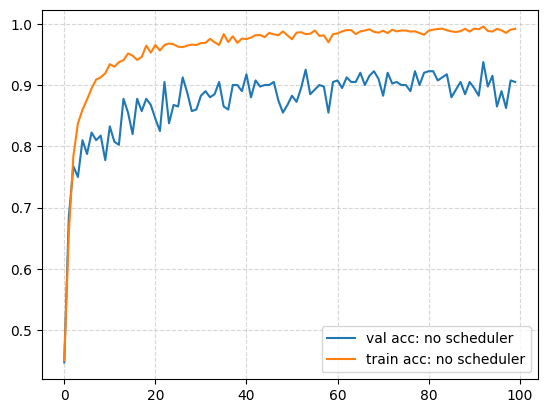

max val acc:  0.9375


In [6]:
plt.plot(range(len(history1['valid_accuracy'])), history1['valid_accuracy'], label="val acc: no scheduler")

plt.plot(range(len(history1['train_accuracy'])), history1['train_accuracy'], label='train acc: no scheduler')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val acc: ", np.max(history1['valid_accuracy']))

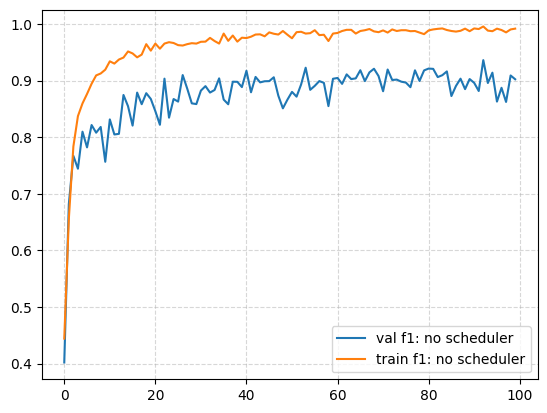

max val f1:  0.9360972046852112


In [33]:
plt.plot(range(len(history1['valid_macro_f1'])), history1['valid_macro_f1'], label="val f1: no scheduler")

plt.plot(range(len(history1['train_macro_f1'])), history1['train_macro_f1'], label='train f1: no scheduler')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val f1: ", np.max(history1['valid_macro_f1']))

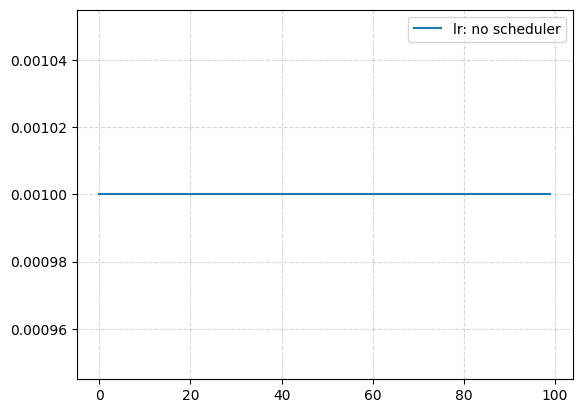

In [11]:
plt.plot(range(len(history1['learning_rates'])), history1['learning_rates'], label="lr: no scheduler")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
torch.manual_seed(42)
EPOCHS = 100
xception_model2 = create_model('small-xception1', 8).to(device)
optimizer = torch.optim.AdamW(xception_model2.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history2 = train(model=xception_model2, optimizer=optimizer, accuracy_metric=accuracy_metric, f1_metric=f1_metric, loss_fn=criterion,
      train_loader=train_loader, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=7, factor=0.7, use_scheduler=True)

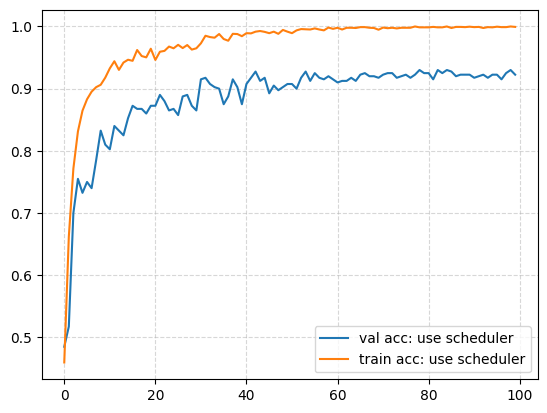

max val acc:  0.9300000071525574


In [13]:
plt.plot(range(len(history2['valid_accuracy'])), history2['valid_accuracy'], label="val acc: use scheduler")

plt.plot(range(len(history2['train_accuracy'])), history2['train_accuracy'], label='train acc: use scheduler')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val acc: ", np.max(history2['valid_accuracy']))

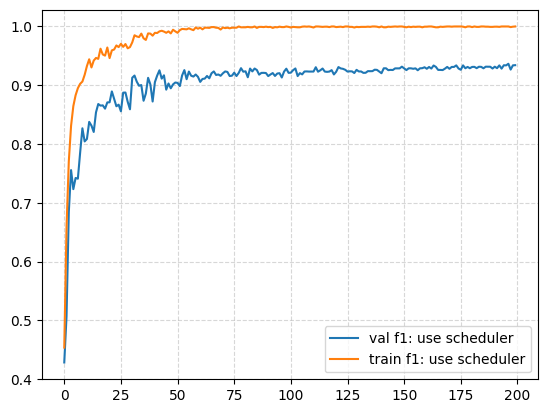

max val f1:  0.9365934133529663


In [34]:
plt.plot(range(len(history2['valid_macro_f1'])), history2['valid_macro_f1'], label="val f1: use scheduler")

plt.plot(range(len(history2['train_macro_f1'])), history2['train_macro_f1'], label='train f1: use scheduler')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val f1: ", np.max(history2['valid_macro_f1']))

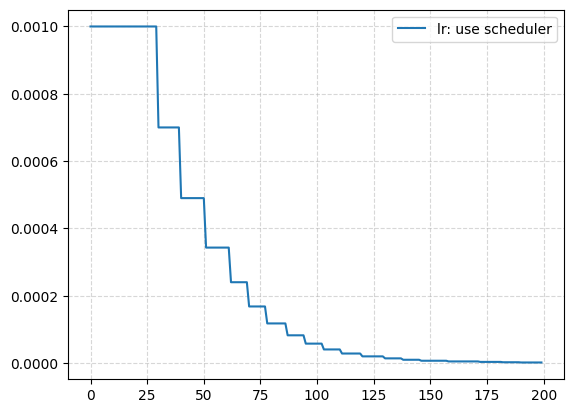

In [15]:
plt.plot(range(len(history2['learning_rates'])), history2['learning_rates'], label="lr: use scheduler")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
torch.manual_seed(42)
EPOCHS = 100
xception_model3 = create_model('small-xception1', 8).to(device)
optimizer = torch.optim.AdamW(xception_model3.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history3 = train(model=xception_model3, optimizer=optimizer, accuracy_metric=accuracy_metric, f1_metric=f1_metric, loss_fn=criterion,
      train_loader=train_loader, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=10, factor=0.9, use_scheduler=True)

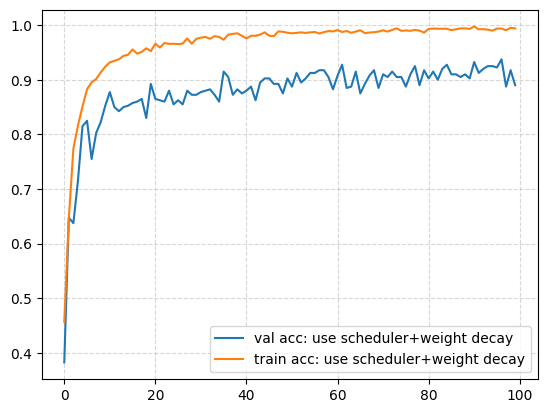

max val acc:  0.9375


In [17]:
plt.plot(range(len(history3['valid_accuracy'])), history3['valid_accuracy'], label="val acc: use scheduler+weight decay")

plt.plot(range(len(history3['train_accuracy'])), history3['train_accuracy'], label='train acc: use scheduler+weight decay')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val acc: ", np.max(history3['valid_accuracy']))


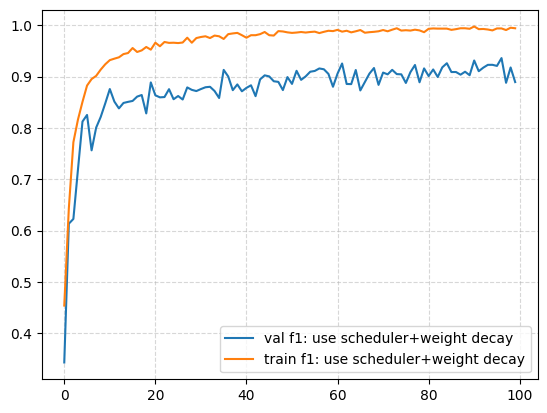

max val f1:  0.9360014200210571


In [35]:
plt.plot(range(len(history3['valid_macro_f1'])), history3['valid_macro_f1'], label="val f1: use scheduler+weight decay")

plt.plot(range(len(history3['train_macro_f1'])), history3['train_macro_f1'], label='train f1: use scheduler+weight decay')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val f1: ", np.max(history3['valid_macro_f1']))

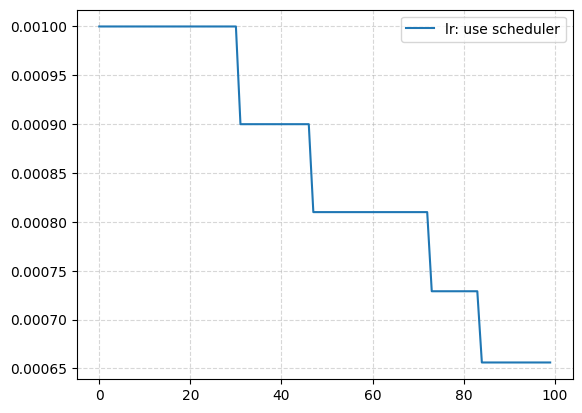

In [19]:
plt.plot(range(len(history3['learning_rates'])), history3['learning_rates'], label="lr: use scheduler")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
torch.manual_seed(42)
EPOCHS = 100
xception_model4 = create_model('small-xception1', 8).to(device)
optimizer = torch.optim.AdamW(xception_model4.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history4 = train(model=xception_model4, optimizer=optimizer, loss_fn=criterion,
      train_loader=train_loader, accuracy_metric=accuracy_metric, f1_metric=f1_metric, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=7, factor=0.7, use_scheduler=False)

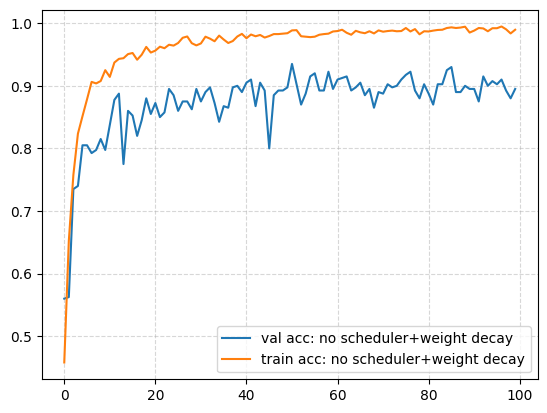

max val acc:  0.9350000023841858


In [21]:
plt.plot(range(len(history4['valid_accuracy'])), history4['valid_accuracy'], label="val acc: no scheduler+weight decay")

plt.plot(range(len(history4['train_accuracy'])), history4['train_accuracy'], label='train acc: no scheduler+weight decay')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val acc: ", np.max(history4['valid_accuracy']))


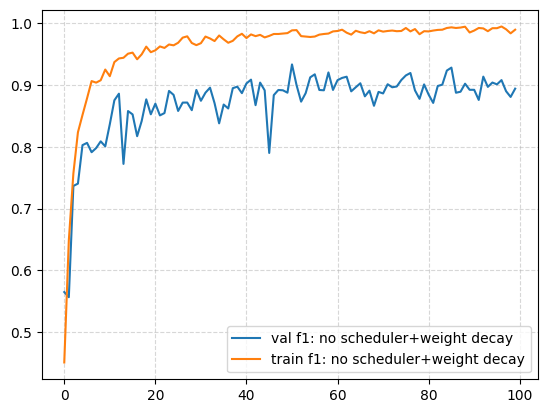

max val f1:  0.9333853125572205


In [36]:
plt.plot(range(len(history4['valid_macro_f1'])), history4['valid_macro_f1'], label="val f1: no scheduler+weight decay")

plt.plot(range(len(history4['train_macro_f1'])), history4['train_macro_f1'], label='train f1: no scheduler+weight decay')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val f1: ", np.max(history4['valid_macro_f1']))

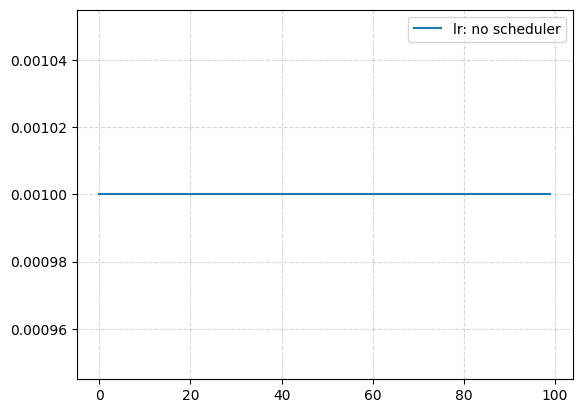

In [23]:
plt.plot(range(len(history4['learning_rates'])), history4['learning_rates'], label="lr: no scheduler")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [24]:
torch.manual_seed(42)
EPOCHS = 100
xception_model5 = create_model('small-xception1', 8, 0.5).to(device)
optimizer = torch.optim.AdamW(xception_model5.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history5 = train(model=xception_model5, optimizer=optimizer, loss_fn=criterion,
      train_loader=train_loader, accuracy_metric=accuracy_metric, f1_metric=f1_metric, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=10, factor=0.9, use_scheduler=True)

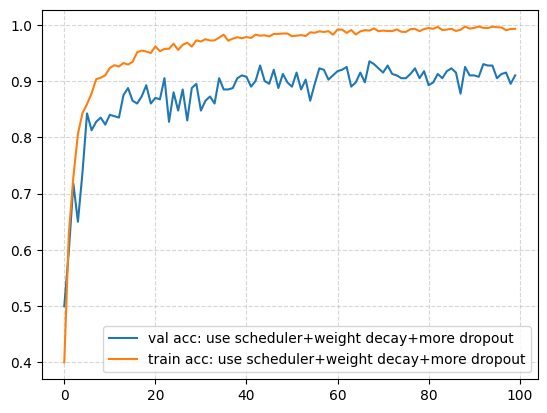

max val acc:  0.9350000023841858


In [26]:
plt.plot(range(len(history5['valid_accuracy'])), history5['valid_accuracy'], label="val acc: use scheduler+weight decay+more dropout")

plt.plot(range(len(history5['train_accuracy'])), history5['train_accuracy'], label='train acc: use scheduler+weight decay+more dropout')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val acc: ", np.max(history5['valid_accuracy']))


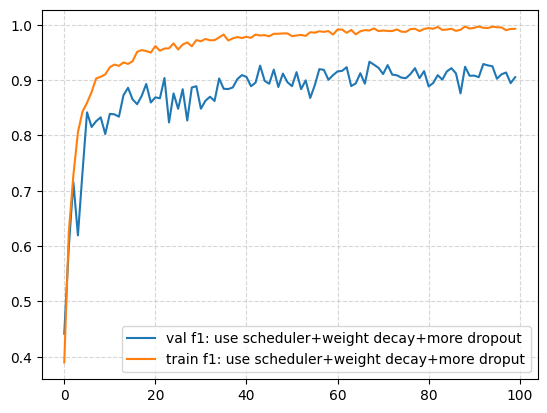

max val f1:  0.9331713914871216


In [37]:
plt.plot(range(len(history5['valid_macro_f1'])), history5['valid_macro_f1'], label="val f1: use scheduler+weight decay+more dropout")

plt.plot(range(len(history5['train_macro_f1'])), history5['train_macro_f1'], label='train f1: use scheduler+weight decay+more droput')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val f1: ", np.max(history5['valid_macro_f1']))

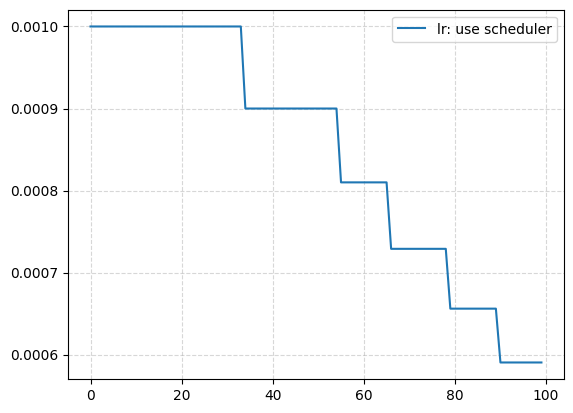

In [28]:
plt.plot(range(len(history5['learning_rates'])), history5['learning_rates'], label="lr: use scheduler")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [29]:
torch.manual_seed(42)
EPOCHS = 100
xception_model6 = create_model('small-xception1', 8).to(device)
optimizer = torch.optim.AdamW(xception_model6.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history6 = train(model=xception_model6, optimizer=optimizer, loss_fn=criterion,
      train_loader=train_loader, accuracy_metric=accuracy_metric, f1_metric=f1_metric, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=10, factor=0.9, use_scheduler=True, cosine_annealing=True)

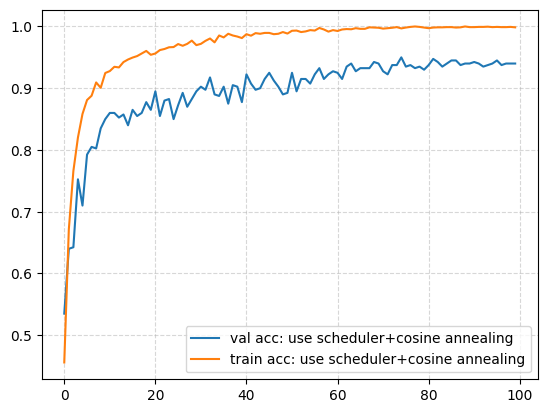

max val acc:  0.949999988079071


In [30]:
plt.plot(range(len(history6['valid_accuracy'])), history6['valid_accuracy'], label="val acc: use scheduler+cosine annealing")

plt.plot(range(len(history6['train_accuracy'])), history6['train_accuracy'], label='train acc: use scheduler+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val acc: ", np.max(history6['valid_accuracy']))


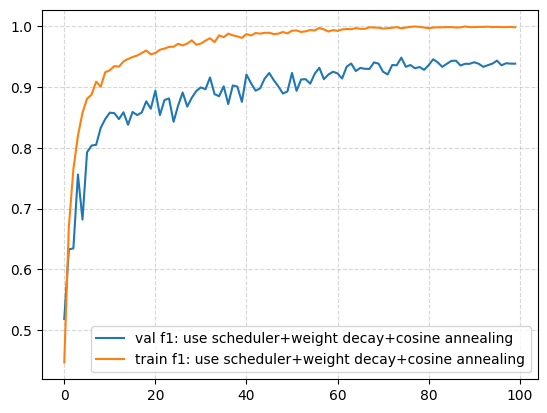

max val f1:  0.9486419558525085


In [31]:
plt.plot(range(len(history6['valid_macro_f1'])), history6['valid_macro_f1'], label="val f1: use scheduler+weight decay+cosine annealing")

plt.plot(range(len(history6['train_macro_f1'])), history6['train_macro_f1'], label='train f1: use scheduler+weight decay+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val f1: ", np.max(history6['valid_macro_f1']))

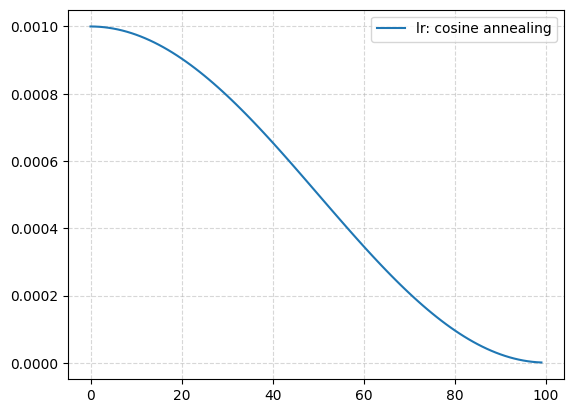

In [32]:
plt.plot(range(len(history6['learning_rates'])), history6['learning_rates'], label="lr: cosine annealing")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
torch.manual_seed(42)
EPOCHS = 100
xception_model7 = create_model('small-xception1', 8).to(device)
optimizer = torch.optim.AdamW(xception_model7.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history7 = train(model=xception_model7, optimizer=optimizer, loss_fn=criterion,
      train_loader=train_loader, accuracy_metric=accuracy_metric, f1_metric=f1_metric, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=10, factor=0.9, use_scheduler=True, cosine_annealing=True)

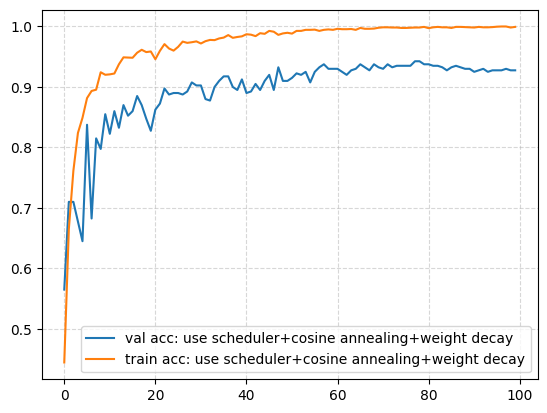

max val acc:  0.9424999952316284


In [39]:
plt.plot(range(len(history7['valid_accuracy'])), history7['valid_accuracy'], label="val acc: use scheduler+cosine annealing+weight decay")

plt.plot(range(len(history7['train_accuracy'])), history7['train_accuracy'], label='train acc: use scheduler+cosine annealing+weight decay')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val acc: ", np.max(history7['valid_accuracy']))


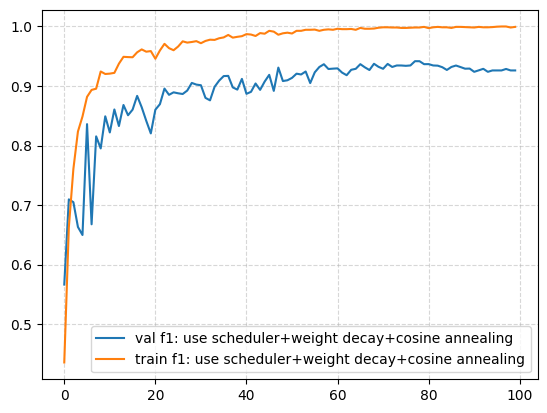

max val f1:  0.9416834712028503


In [40]:
plt.plot(range(len(history7['valid_macro_f1'])), history7['valid_macro_f1'], label="val f1: use scheduler+weight decay+cosine annealing")

plt.plot(range(len(history7['train_macro_f1'])), history7['train_macro_f1'], label='train f1: use scheduler+weight decay+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val f1: ", np.max(history7['valid_macro_f1']))

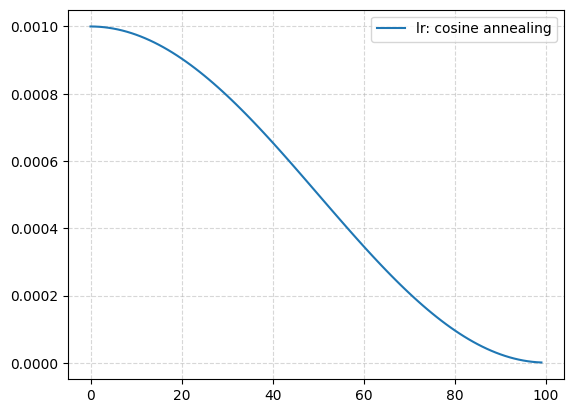

In [41]:
plt.plot(range(len(history7['learning_rates'])), history7['learning_rates'], label="lr: cosine annealing")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
torch.manual_seed(42)
EPOCHS = 100
xception_model8 = create_model('small-xception1', 8).to(device)
optimizer = torch.optim.AdamW(xception_model8.parameters(), lr=1e-3, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history8 = train(model=xception_model8, optimizer=optimizer, loss_fn=criterion,
      train_loader=train_loader, accuracy_metric=accuracy_metric, f1_metric=f1_metric, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=10, factor=0.9, use_scheduler=True, cosine_annealing=True)

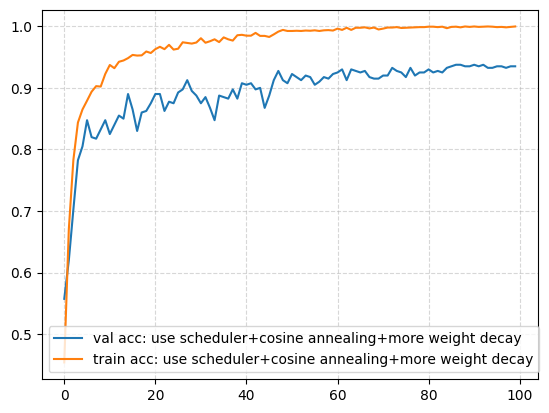

max val acc:  0.9375


In [5]:
plt.plot(range(len(history8['valid_accuracy'])), history8['valid_accuracy'], label="val acc: use scheduler+cosine annealing+more weight decay")

plt.plot(range(len(history8['train_accuracy'])), history8['train_accuracy'], label='train acc: use scheduler+cosine annealing+more weight decay')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val acc: ", np.max(history8['valid_accuracy']))


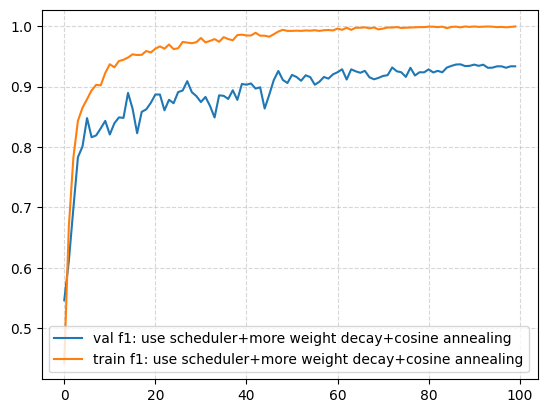

max val f1:  0.9369484186172485


In [6]:
plt.plot(range(len(history8['valid_macro_f1'])), history8['valid_macro_f1'], label="val f1: use scheduler+more weight decay+cosine annealing")

plt.plot(range(len(history8['train_macro_f1'])), history8['train_macro_f1'], label='train f1: use scheduler+more weight decay+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("max val f1: ", np.max(history8['valid_macro_f1']))

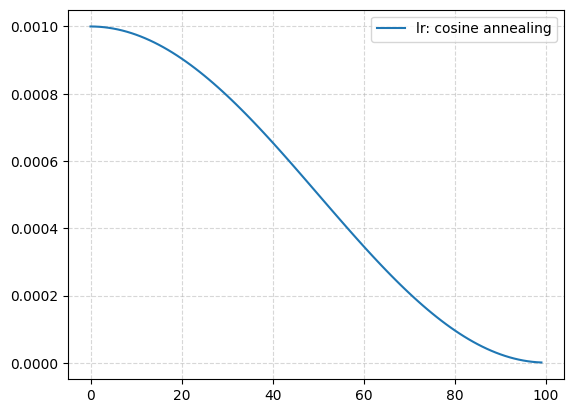

In [7]:
plt.plot(range(len(history8['learning_rates'])), history8['learning_rates'], label="lr: cosine annealing")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
torch.manual_seed(42)
EPOCHS = 100
xception_model9 = create_model('small-xception2', 8, dropout=0.2).to(device)
optimizer = torch.optim.AdamW(xception_model9.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history9 = train(model=xception_model9, optimizer=optimizer, loss_fn=criterion,
      train_loader=train_loader, accuracy_metric=accuracy_metric, f1_metric=f1_metric, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=10, factor=0.9, use_scheduler=True, cosine_annealing=True)

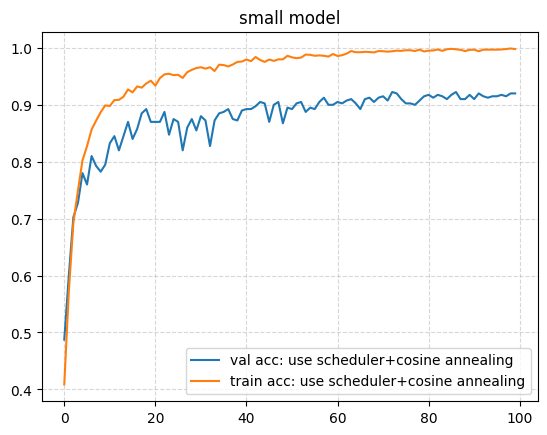

max val acc:  0.9225000143051147


In [10]:
plt.plot(range(len(history9['valid_accuracy'])), history9['valid_accuracy'], label="val acc: use scheduler+cosine annealing")

plt.plot(range(len(history9['train_accuracy'])), history9['train_accuracy'], label='train acc: use scheduler+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('small model')
plt.show()

print("max val acc: ", np.max(history9['valid_accuracy']))


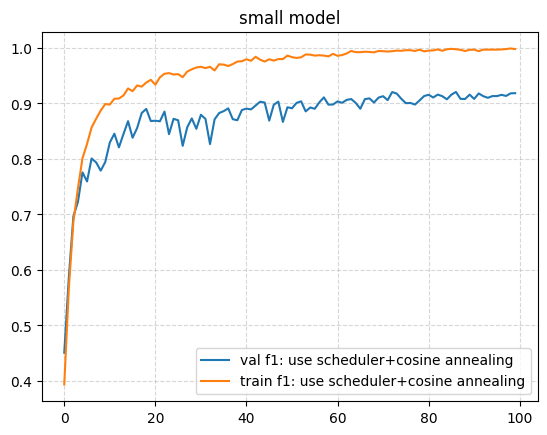

max val f1:  0.9206150770187378


In [15]:
plt.plot(range(len(history9['valid_macro_f1'])), history9['valid_macro_f1'], label="val f1: use scheduler+cosine annealing")

plt.plot(range(len(history9['train_macro_f1'])), history9['train_macro_f1'], label='train f1: use scheduler+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('small model')
plt.show()

print("max val f1: ", np.max(history9['valid_macro_f1']))

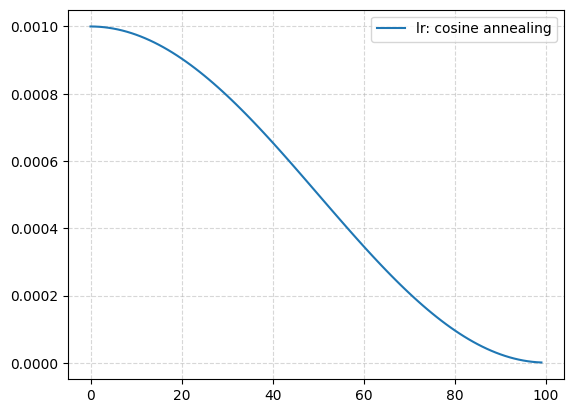

In [12]:
plt.plot(range(len(history9['learning_rates'])), history9['learning_rates'], label="lr: cosine annealing")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [13]:
torch.manual_seed(42)
EPOCHS = 100
xception_model10 = create_model('small-xception3', 8, dropout=0.2).to(device)
optimizer = torch.optim.AdamW(xception_model10.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history10 = train(model=xception_model10, optimizer=optimizer, loss_fn=criterion,
      train_loader=train_loader, accuracy_metric=accuracy_metric, f1_metric=f1_metric, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=10, factor=0.9, use_scheduler=True, cosine_annealing=True)

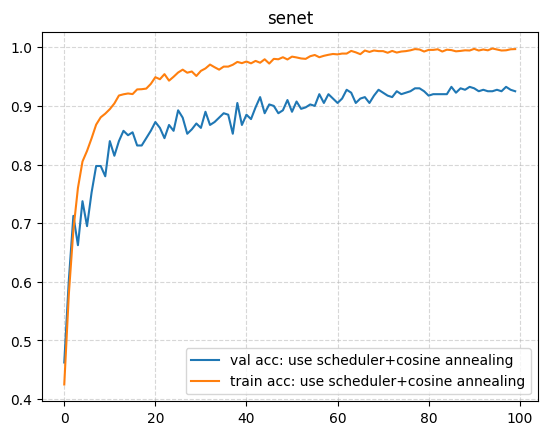

max val acc:  0.9325000047683716


In [14]:
plt.plot(range(len(history10['valid_accuracy'])), history10['valid_accuracy'], label="val acc: use scheduler+cosine annealing")

plt.plot(range(len(history10['train_accuracy'])), history10['train_accuracy'], label='train acc: use scheduler+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('senet')
plt.show()

print("max val acc: ", np.max(history10['valid_accuracy']))


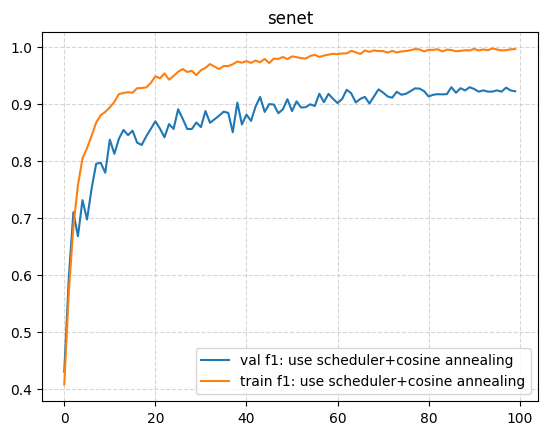

max val f1:  0.9299514889717102


In [16]:
plt.plot(range(len(history10['valid_macro_f1'])), history10['valid_macro_f1'], label="val f1: use scheduler+cosine annealing")

plt.plot(range(len(history10['train_macro_f1'])), history10['train_macro_f1'], label='train f1: use scheduler+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('senet')
plt.show()

print("max val f1: ", np.max(history10['valid_macro_f1']))

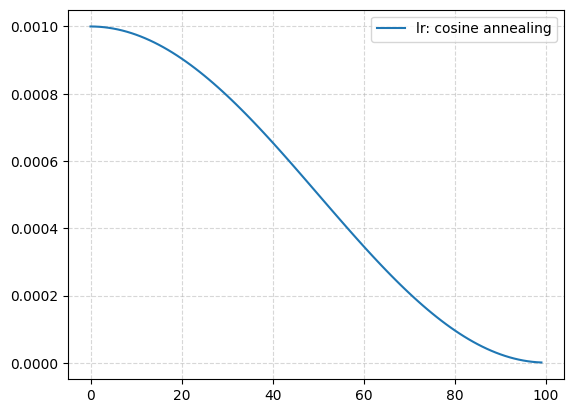

In [17]:
plt.plot(range(len(history10['learning_rates'])), history10['learning_rates'], label="lr: cosine annealing")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
torch.manual_seed(42)
EPOCHS = 100
xception_model11 = create_model('small-xception3', 8, dropout=0.2).to(device)
optimizer = torch.optim.AdamW(xception_model11.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

history11 = train(model=xception_model11, optimizer=optimizer, loss_fn=criterion,
      train_loader=train_loader, accuracy_metric=accuracy_metric, f1_metric=f1_metric, valid_loader=valid_loader, 
      n_epochs=EPOCHS, device=device, patience=10, factor=0.9, use_scheduler=True, cosine_annealing=True)


plt.plot(range(len(history11['valid_accuracy'])), history11['valid_accuracy'], label="val acc: use scheduler+cosine annealing")

plt.plot(range(len(history11['train_accuracy'])), history11['train_accuracy'], label='train acc: use scheduler+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('senet+weight decay')
plt.show()

print("max val acc: ", np.max(history11['valid_accuracy']))

plt.plot(range(len(history11['valid_macro_f1'])), history11['valid_macro_f1'], label="val f1: use scheduler+cosine annealing")

plt.plot(range(len(history11['train_macro_f1'])), history11['train_macro_f1'], label='train f1: use scheduler+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('senet+weight decay')
plt.show()

print("max val f1: ", np.max(history11['valid_macro_f1']))



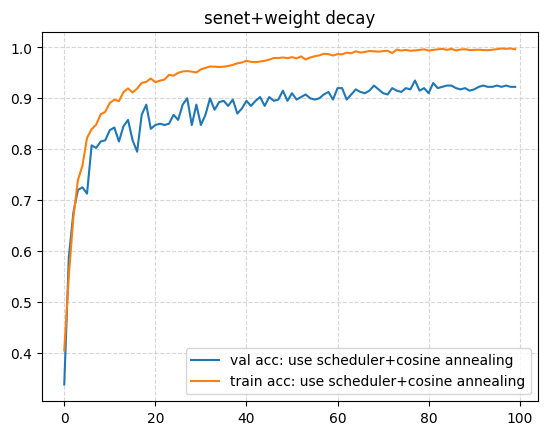

max val acc:  0.9350000023841858


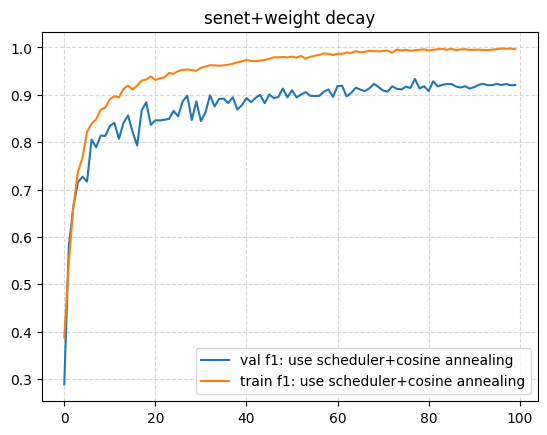

max val f1:  0.9335864782333374


In [19]:
plt.plot(range(len(history11['valid_accuracy'])), history11['valid_accuracy'], label="val acc: use scheduler+cosine annealing")

plt.plot(range(len(history11['train_accuracy'])), history11['train_accuracy'], label='train acc: use scheduler+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('senet+weight decay')
plt.show()

print("max val acc: ", np.max(history11['valid_accuracy']))

plt.plot(range(len(history11['valid_macro_f1'])), history11['valid_macro_f1'], label="val f1: use scheduler+cosine annealing")

plt.plot(range(len(history11['train_macro_f1'])), history11['train_macro_f1'], label='train f1: use scheduler+cosine annealing')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('senet+weight decay')
plt.show()

print("max val f1: ", np.max(history11['valid_macro_f1']))



# Train best model

In [ ]:
torch.manual_seed(42)
EPOCHS = 500
xception_model = create_model('small-xception1', 8).to(device)
optimizer = torch.optim.AdamW(xception_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

best_xception_history = train(model=xception_model, 
                              optimizer=optimizer, loss_fn=criterion,
                              train_loader=train_loader, accuracy_metric=accuracy_metric, 
                              f1_metric=f1_metric, valid_loader=valid_loader, 
                              n_epochs=EPOCHS, device=device, patience=10, 
                              factor=0.9, use_scheduler=True, cosine_annealing=True, 
                              path_to_save="models/ best_xception_model.pth")

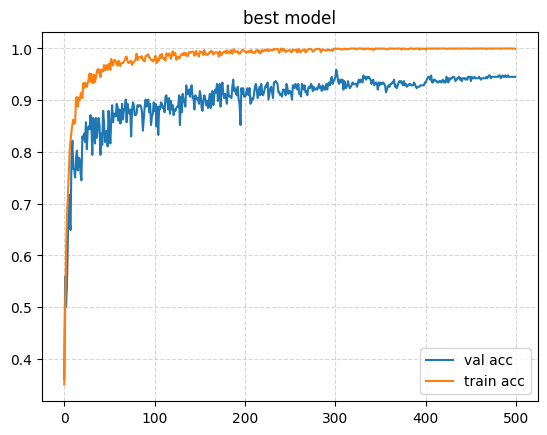

max val acc:  0.9589040875434875


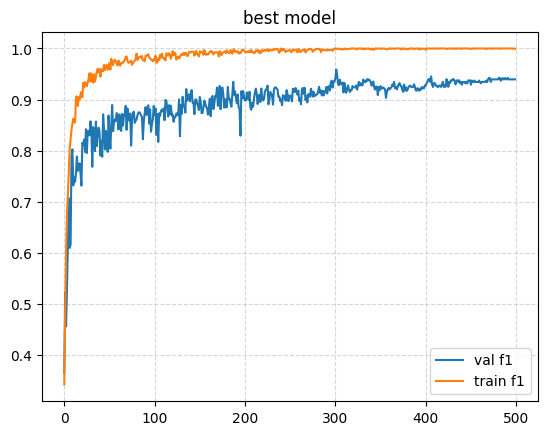

max val f1:  0.9587578773498535


In [5]:
plt.plot(range(len(best_xception_history['valid_accuracy'])), best_xception_history['valid_accuracy'], label="val acc")

plt.plot(range(len(best_xception_history['train_accuracy'])), best_xception_history['train_accuracy'], label='train acc')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('best model')
plt.show()

print("max val acc: ", np.max(best_xception_history['valid_accuracy']))

plt.plot(range(len(best_xception_history['valid_macro_f1'])), best_xception_history['valid_macro_f1'], label="val f1")

plt.plot(range(len(best_xception_history['train_macro_f1'])), best_xception_history['train_macro_f1'], label='train f1')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('best model')
plt.show()

print("max val f1: ", np.max(best_xception_history['valid_macro_f1']))

# Early Stopping 

In [ ]:
torch.manual_seed(42)
EPOCHS = 500
senet_model = create_model('small-xception3', 8).to(device)
optimizer = torch.optim.AdamW(senet_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

best_senet_history = train(model=senet_model, 
                              optimizer=optimizer, loss_fn=criterion,
                              train_loader=train_loader, accuracy_metric=accuracy_metric, 
                              f1_metric=f1_metric, valid_loader=valid_loader, 
                              n_epochs=EPOCHS, device=device, patience=10, 
                              factor=0.9, use_scheduler=True, cosine_annealing=True, 
                              path_to_save="models/ best_senet_model.pth")

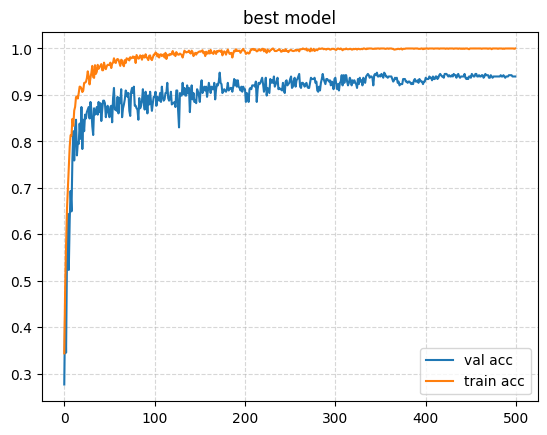

max val acc:  0.9479451775550842


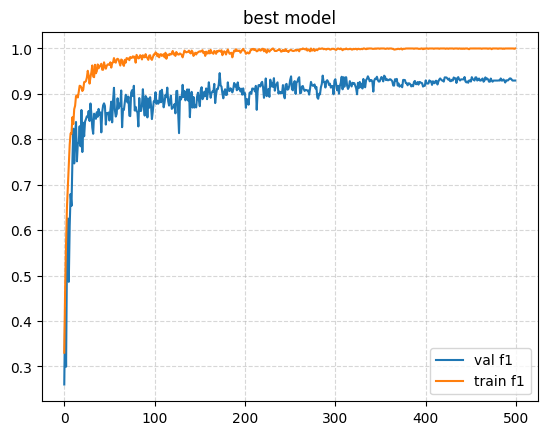

max val f1:  0.9457564353942871


In [5]:
plt.plot(range(len(best_senet_history['valid_accuracy'])), best_senet_history['valid_accuracy'], label="val acc")

plt.plot(range(len(best_senet_history['train_accuracy'])), best_senet_history['train_accuracy'], label='train acc')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('best model')
plt.show()

print("max val acc: ", np.max(best_senet_history['valid_accuracy']))

plt.plot(range(len(best_senet_history['valid_macro_f1'])), best_senet_history['valid_macro_f1'], label="val f1")

plt.plot(range(len(best_senet_history['train_macro_f1'])), best_senet_history['train_macro_f1'], label='train f1')

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title('best model')
plt.show()

print("max val f1: ", np.max(best_senet_history['valid_macro_f1']))



In [ ]:
vgg = create_model("vgg", 8)
vgg, vgg_history = train_vgg(
    model=vgg,
    train_loader=train_loader,
    valid_loader=valid_loader,
    device=device,
    num_classes=8,
    n_epochs=60,
    lr_backbone=1e-4,
    lr_head=1e-3,
    n_frozen=24,
    label_smoothing=0.1,
    scheduler_type="cosine",
    early_stop_patience=15,
    save_path="models/vgg.pth",
)

2026-10-08 15:58:51 | INFO     | src.train | Trainable params: 126,658,056 / 134,293,320
2026-10-08 16:00:15 | INFO     | src.train | Epoch 001/60 | train loss 1.2661 acc 0.6453 f1 0.6448 | val loss 0.5277 acc 0.8603 f1 0.8508 | lr bb 5.00e-05 head 5.00e-04 | grad 9.28
2026-10-08 16:01:33 | INFO     | src.train | Epoch 002/60 | train loss 0.7845 acc 0.9000 f1 0.9006 | val loss 0.4307 acc 0.9096 f1 0.9035 | lr bb 1.00e-04 head 1.00e-03 | grad 5.72
2026-10-08 16:02:50 | INFO     | src.train | Epoch 003/60 | train loss 0.7468 acc 0.9078 f1 0.9081 | val loss 0.4428 acc 0.9014 f1 0.8872 | lr bb 1.00e-04 head 1.00e-03 | grad 5.00
2026-10-08 16:03:24 | INFO     | src.train | Epoch 004/60 | train loss 0.6590 acc 0.9445 f1 0.9447 | val loss 0.3724 acc 0.9288 f1 0.9140 | lr bb 9.99e-05 head 9.99e-04 | grad 3.59
2026-10-08 16:04:14 | INFO     | src.train | Epoch 005/60 | train loss 0.6193 acc 0.9664 f1 0.9664 | val loss 0.3396 acc 0.9452 f1 0.9337 | lr bb 9.97e-05 head 9.97e-04 | grad 3.17
2026-1

In [ ]:
torch.manual_seed(42)
EPOCHS = 500
vgg = create_model('vgg', 8).to(device)
optimizer = torch.optim.AdamW(vgg.parameters(), lr=1e-2)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
f1_metric = torchmetrics.F1Score(
    task="multiclass",
    num_classes=8,
    average="macro",
).to(device)

for p in vgg.features[:24].parameters():
    p.requires_grad = False

vgg_history = train(model=vgg, 
                    optimizer=optimizer, 
                    loss_fn=criterion,
                    train_loader=train_loader, 
                    accuracy_metric=accuracy_metric, 
                    f1_metric=f1_metric, 
                    valid_loader=valid_loader, 
                    n_epochs=EPOCHS, 
                    device=device, 
                    patience=10, 
                    factor=0.9, 
                    use_scheduler=True, 
                    #cosine_annealing=True,   
                    path_to_save="models/vgg.pth",
                    layers_to_eval=vgg.features[:24])

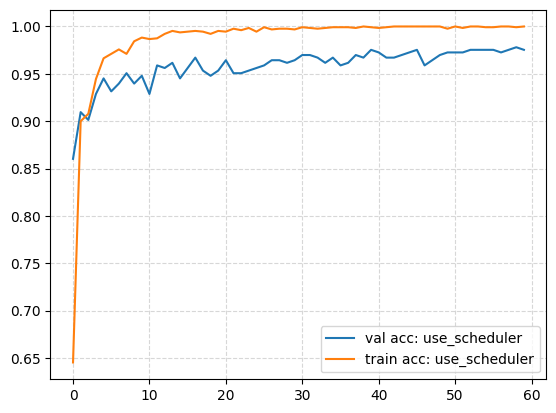

0.9780821800231934


In [6]:
# plt.subplot(121)
plt.plot(range(len(vgg_history['val_acc'])), vgg_history['val_acc'], label="val acc: use_scheduler")
# plt.title('valid_metrics')
# plt.subplot(122)
plt.plot(range(len(vgg_history['train_acc'])), vgg_history['train_acc'], label='train acc: use_scheduler')
# plt.title('train_metrics')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()
print(np.max(vgg_history['val_acc']))

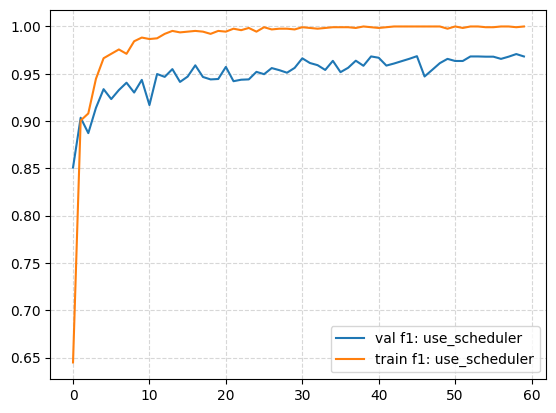

1.0


In [7]:
# plt.subplot(121)
plt.plot(range(len(vgg_history['val_f1'])), vgg_history['val_f1'], label="val f1: use_scheduler")
# plt.title('valid_metrics')
# plt.subplot(122)
plt.plot(range(len(vgg_history['train_f1'])), vgg_history['train_f1'], label='train f1: use_scheduler')
# plt.title('train_metrics')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()
print(np.max(vgg_history['train_f1']))

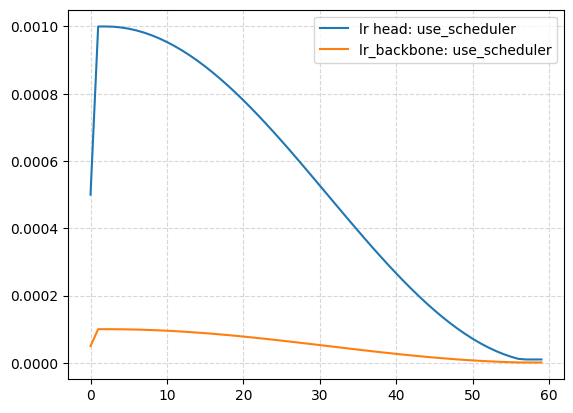

In [9]:
# plt.subplot(121)
plt.plot(range(len(vgg_history['lr_head'])), vgg_history['lr_head'], label="lr head: use_scheduler")
# plt.title('valid_metrics')
# plt.subplot(122)
plt.plot(range(len(vgg_history['lr_backbone'])), vgg_history['lr_backbone'], label='lr_backbone: use_scheduler')
# plt.title('train_metrics')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Plot confusion matrices for both models

In [11]:
vgg = create_model('vgg', 8).to(device)
best_xception_model = create_model('small-xception1', 8).to(device)

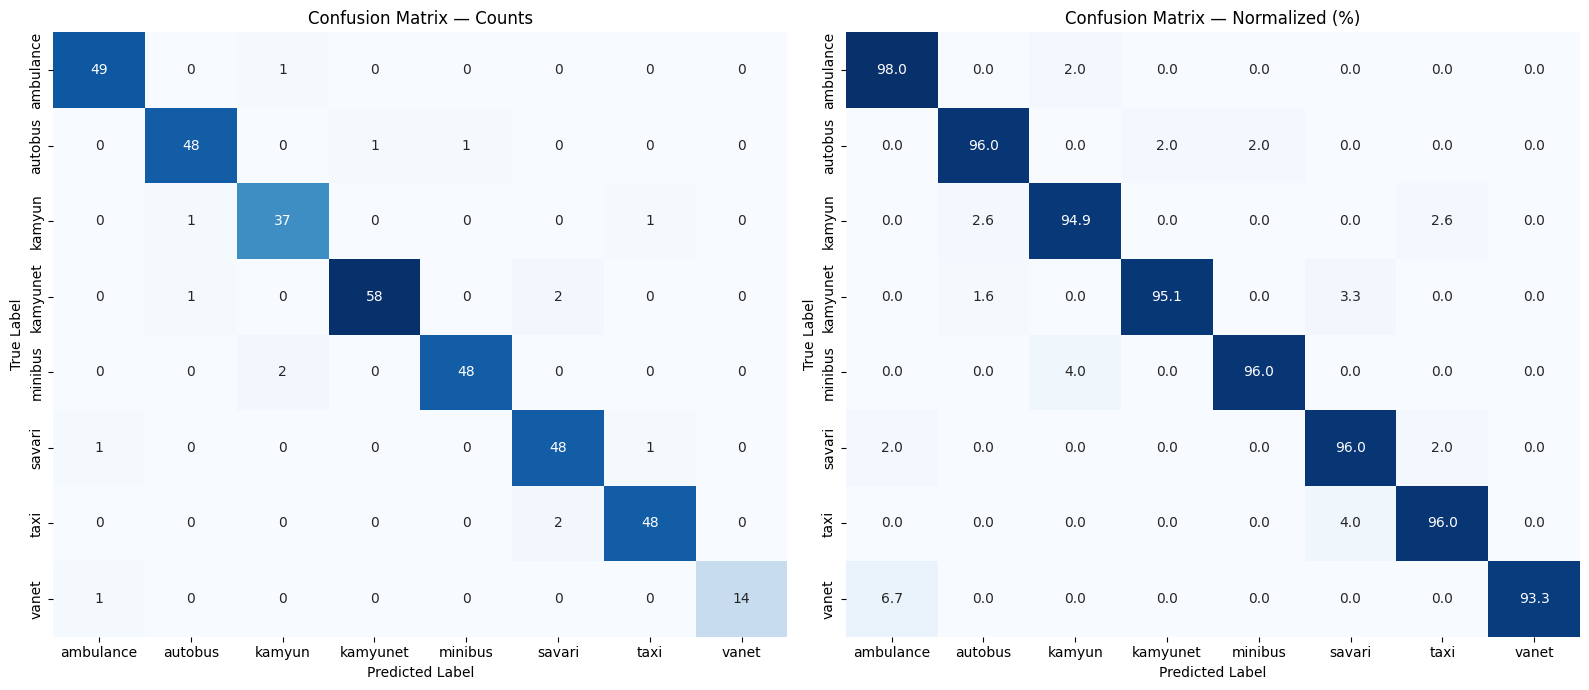

(array([[49,  0,  1,  0,  0,  0,  0,  0],
        [ 0, 48,  0,  1,  1,  0,  0,  0],
        [ 0,  1, 37,  0,  0,  0,  1,  0],
        [ 0,  1,  0, 58,  0,  2,  0,  0],
        [ 0,  0,  2,  0, 48,  0,  0,  0],
        [ 1,  0,  0,  0,  0, 48,  1,  0],
        [ 0,  0,  0,  0,  0,  2, 48,  0],
        [ 1,  0,  0,  0,  0,  0,  0, 14]]),
 array([[         98,           0,           2,           0,           0,           0,           0,           0],
        [          0,          96,           0,           2,           2,           0,           0,           0],
        [          0,      2.5641,      94.872,           0,           0,           0,      2.5641,           0],
        [          0,      1.6393,           0,      95.082,           0,      3.2787,           0,           0],
        [          0,           0,           4,           0,          96,           0,           0,           0],
        [          2,           0,           0,           0,           0,          96,      

In [12]:
plot_confusion_matrices(
    best_xception_model,
    'models/ best_xception_model.pth',
    valid_loader,
    classes,
    device,
)

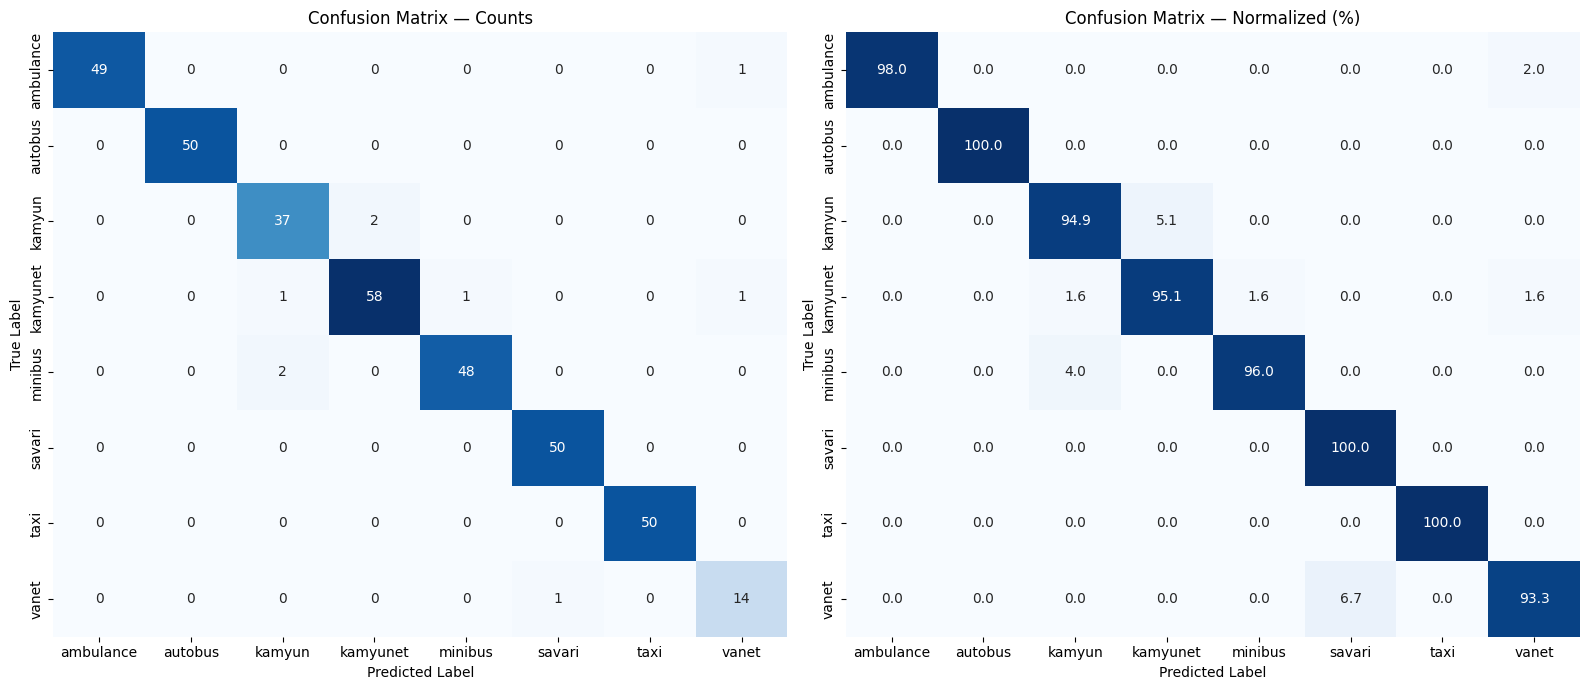

(array([[49,  0,  0,  0,  0,  0,  0,  1],
        [ 0, 50,  0,  0,  0,  0,  0,  0],
        [ 0,  0, 37,  2,  0,  0,  0,  0],
        [ 0,  0,  1, 58,  1,  0,  0,  1],
        [ 0,  0,  2,  0, 48,  0,  0,  0],
        [ 0,  0,  0,  0,  0, 50,  0,  0],
        [ 0,  0,  0,  0,  0,  0, 50,  0],
        [ 0,  0,  0,  0,  0,  1,  0, 14]]),
 array([[         98,           0,           0,           0,           0,           0,           0,           2],
        [          0,         100,           0,           0,           0,           0,           0,           0],
        [          0,           0,      94.872,      5.1282,           0,           0,           0,           0],
        [          0,           0,      1.6393,      95.082,      1.6393,           0,           0,      1.6393],
        [          0,           0,           4,           0,          96,           0,           0,           0],
        [          0,           0,           0,           0,           0,         100,      

In [13]:
plot_confusion_matrices(
    vgg,
    'models/vgg.pth',
    valid_loader,
    classes,
    device,
)

# Plot misclassified images

In [2]:
# plot_misclassified_images(
#     model=best_xception_model,
#     weights_path="models/ best_xception_model.pth",
#     dataloader=valid_loader,
#     class_names=valid_loader.dataset.classes,
#     num_images=11,
# )

In [3]:
# plot_misclassified_images(
#     model=vgg,
#     weights_path="models/vgg.pth",
#     dataloader=valid_loader,
#     class_names=valid_loader.dataset.classes,
#     num_images=11,
# )

# Train to find classes which do not exist in my dataset

In [4]:
def load_weights(model, path, device, weights_only=True):   
    state_dict = torch.load(
            path,
            map_location=device,
            weights_only=weights_only,
    )

    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()
    return model

vgg = create_model('vgg', 8).to(device)
best_xception_model = create_model('small-xception1', 8).to(device)

vgg = load_weights(vgg, "models/vgg.pth", device)
best_xception_model = load_weights(best_xception_model, "models/ best_xception_model.pth", device)
print('models are loaded')

models are loaded


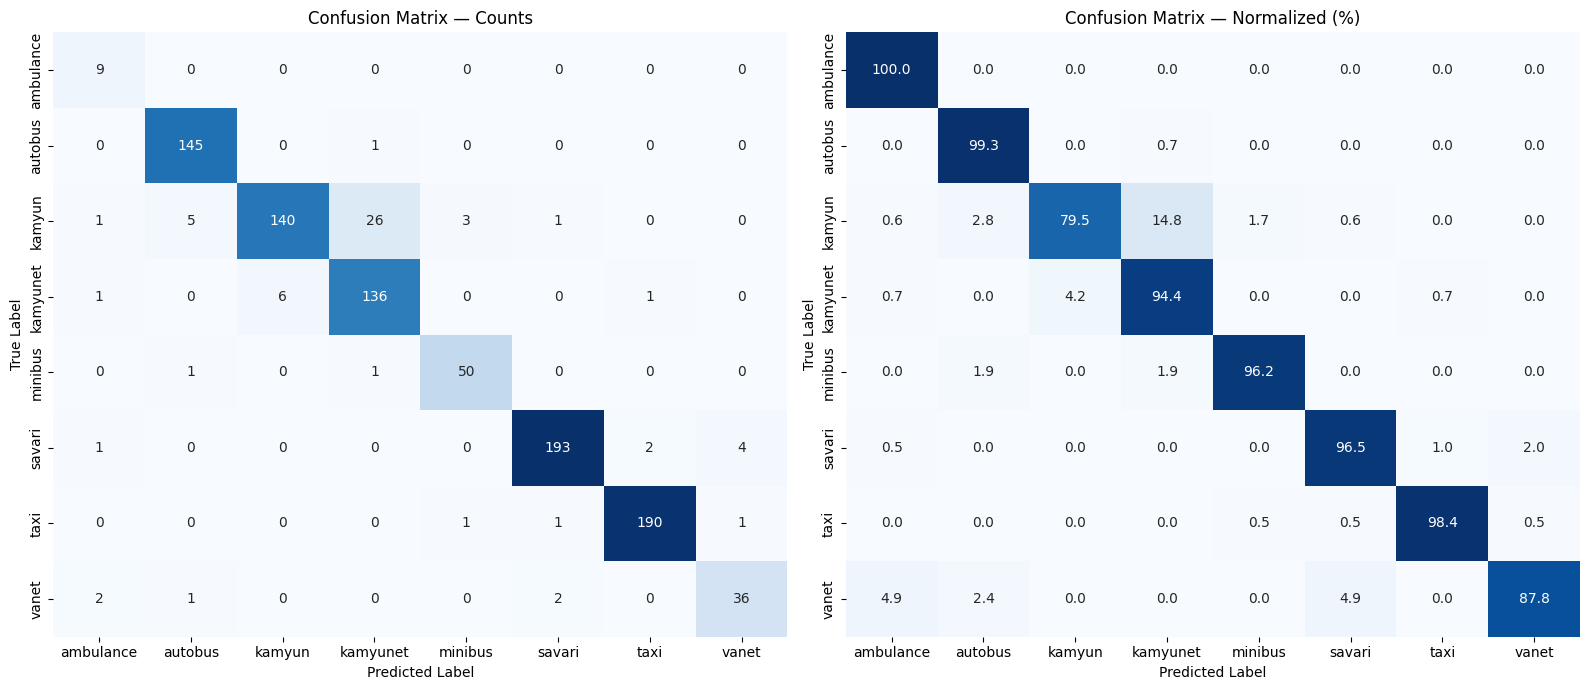

(array([[  9,   0,   0,   0,   0,   0,   0,   0],
        [  0, 145,   0,   1,   0,   0,   0,   0],
        [  1,   5, 140,  26,   3,   1,   0,   0],
        [  1,   0,   6, 136,   0,   0,   1,   0],
        [  0,   1,   0,   1,  50,   0,   0,   0],
        [  1,   0,   0,   0,   0, 193,   2,   4],
        [  0,   0,   0,   0,   1,   1, 190,   1],
        [  2,   1,   0,   0,   0,   2,   0,  36]]),
 array([[        100,           0,           0,           0,           0,           0,           0,           0],
        [          0,      99.315,           0,     0.68493,           0,           0,           0,           0],
        [    0.56818,      2.8409,      79.545,      14.773,      1.7045,     0.56818,           0,           0],
        [    0.69444,           0,      4.1667,      94.444,           0,           0,     0.69444,           0],
        [          0,      1.9231,           0,      1.9231,      96.154,           0,           0,           0],
        [        0.5,       

In [28]:
plot_confusion_matrices(
    best_xception_model,
    'models/ best_xception_model.pth',
    test0,
    test0.dataset.classes,
    device,
)

In [4]:
# plot_misclassified_images(
#     model=best_xception_model,
#     weights_path="models/ best_xception_model.pth",
#     dataloader=test0,
#     class_names=test0.dataset.classes,
#     num_images=11,
# )

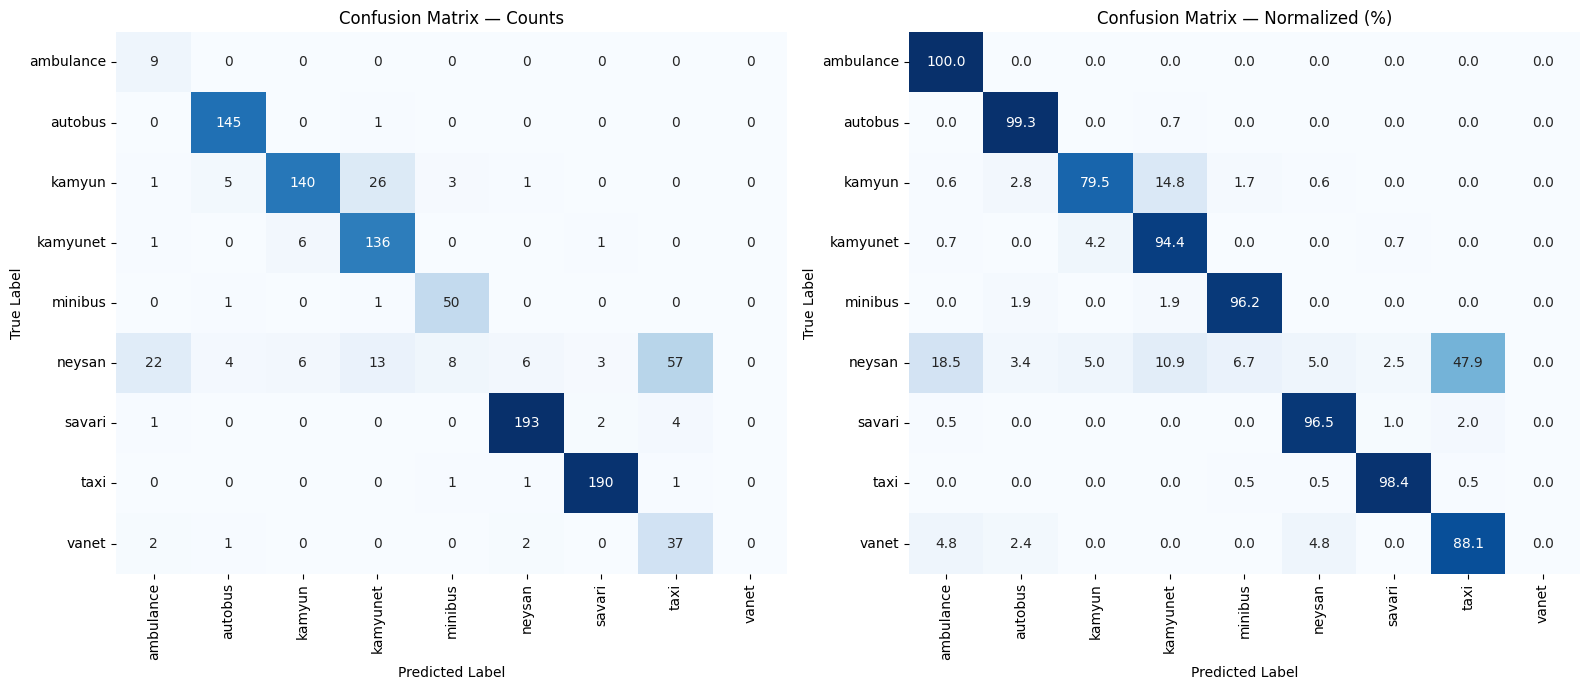

(array([[  9,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0, 145,   0,   1,   0,   0,   0,   0,   0],
        [  1,   5, 140,  26,   3,   1,   0,   0,   0],
        [  1,   0,   6, 136,   0,   0,   1,   0,   0],
        [  0,   1,   0,   1,  50,   0,   0,   0,   0],
        [ 22,   4,   6,  13,   8,   6,   3,  57,   0],
        [  1,   0,   0,   0,   0, 193,   2,   4,   0],
        [  0,   0,   0,   0,   1,   1, 190,   1,   0],
        [  2,   1,   0,   0,   0,   2,   0,  37,   0]]),
 array([[        100,           0,           0,           0,           0,           0,           0,           0,           0],
        [          0,      99.315,           0,     0.68493,           0,           0,           0,           0,           0],
        [    0.56818,      2.8409,      79.545,      14.773,      1.7045,     0.56818,           0,           0,           0],
        [    0.69444,           0,      4.1667,      94.444,           0,           0,     0.69444,           0,          

In [29]:
plot_confusion_matrices(
    best_xception_model,
    'models/ best_xception_model.pth',
    test1,
    test1.dataset.classes,
    device,
)

In [5]:
# plot_misclassified_images(
#     model=best_xception_model,
#     weights_path="models/ best_xception_model.pth",
#     dataloader=test1,
#     class_names=test1.dataset.classes,
#     num_images=11,
# )

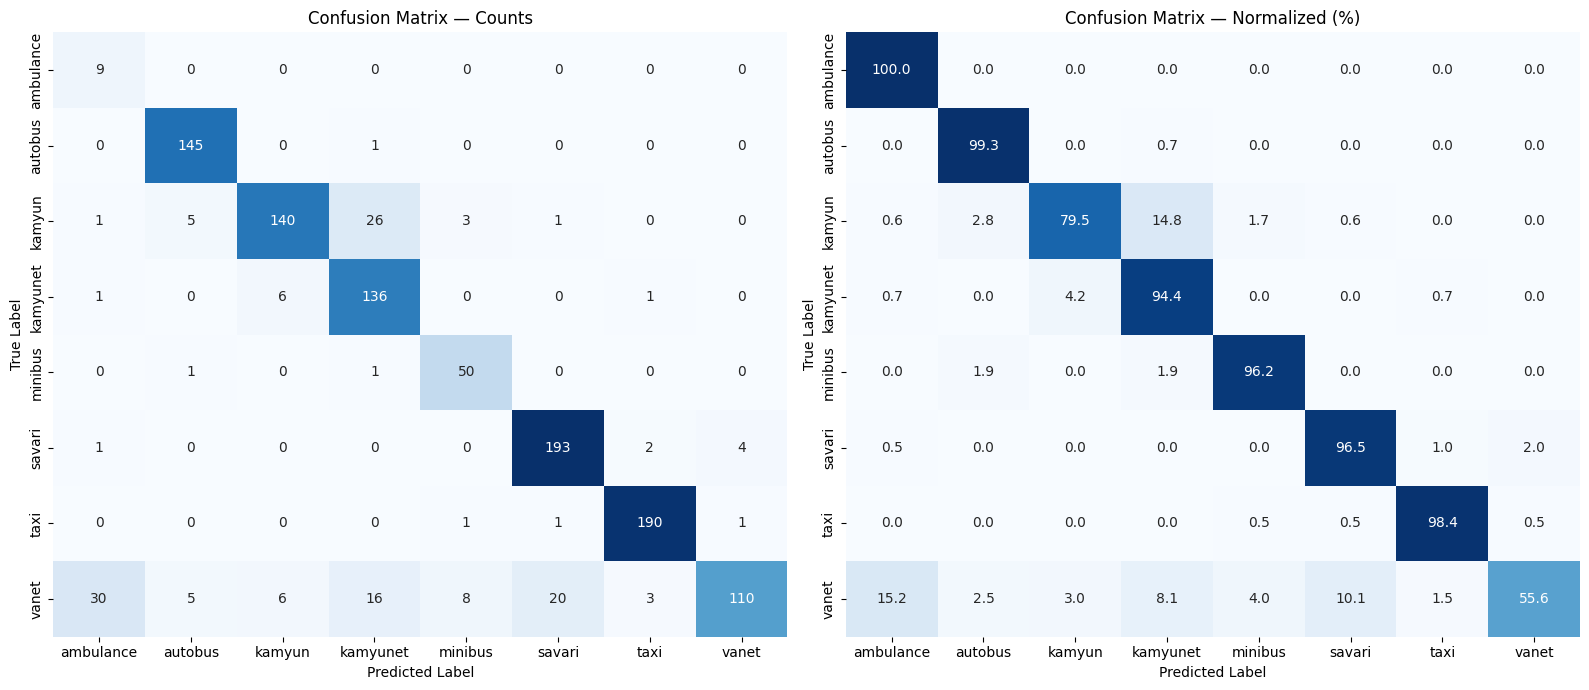

(array([[  9,   0,   0,   0,   0,   0,   0,   0],
        [  0, 145,   0,   1,   0,   0,   0,   0],
        [  1,   5, 140,  26,   3,   1,   0,   0],
        [  1,   0,   6, 136,   0,   0,   1,   0],
        [  0,   1,   0,   1,  50,   0,   0,   0],
        [  1,   0,   0,   0,   0, 193,   2,   4],
        [  0,   0,   0,   0,   1,   1, 190,   1],
        [ 30,   5,   6,  16,   8,  20,   3, 110]]),
 array([[        100,           0,           0,           0,           0,           0,           0,           0],
        [          0,      99.315,           0,     0.68493,           0,           0,           0,           0],
        [    0.56818,      2.8409,      79.545,      14.773,      1.7045,     0.56818,           0,           0],
        [    0.69444,           0,      4.1667,      94.444,           0,           0,     0.69444,           0],
        [          0,      1.9231,           0,      1.9231,      96.154,           0,           0,           0],
        [        0.5,       

In [30]:
plot_confusion_matrices(
    best_xception_model,
    'models/ best_xception_model.pth',
    test2,
    test2.dataset.classes,
    device,
)

In [6]:
# plot_misclassified_images(
#     model=best_xception_model,
#     weights_path="models/ best_xception_model.pth",
#     dataloader=test2,
#     class_names=test2.dataset.classes,
#     num_images=11,
# )

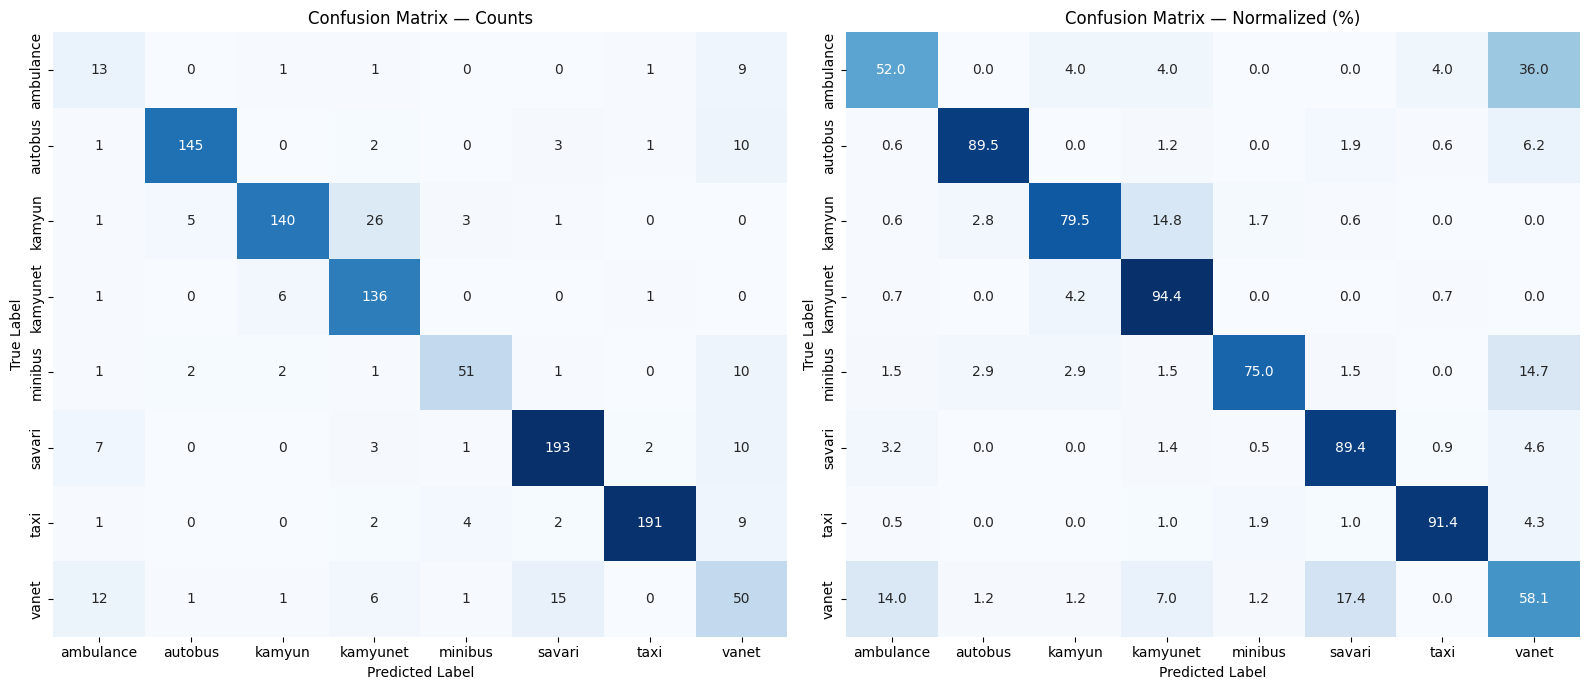

(array([[ 13,   0,   1,   1,   0,   0,   1,   9],
        [  1, 145,   0,   2,   0,   3,   1,  10],
        [  1,   5, 140,  26,   3,   1,   0,   0],
        [  1,   0,   6, 136,   0,   0,   1,   0],
        [  1,   2,   2,   1,  51,   1,   0,  10],
        [  7,   0,   0,   3,   1, 193,   2,  10],
        [  1,   0,   0,   2,   4,   2, 191,   9],
        [ 12,   1,   1,   6,   1,  15,   0,  50]]),
 array([[         52,           0,           4,           4,           0,           0,           4,          36],
        [    0.61728,      89.506,           0,      1.2346,           0,      1.8519,     0.61728,      6.1728],
        [    0.56818,      2.8409,      79.545,      14.773,      1.7045,     0.56818,           0,           0],
        [    0.69444,           0,      4.1667,      94.444,           0,           0,     0.69444,           0],
        [     1.4706,      2.9412,      2.9412,      1.4706,          75,      1.4706,           0,      14.706],
        [     3.2407,       

In [32]:
plot_confusion_matrices(
    best_xception_model,
    'models/ best_xception_model.pth',
    test3,
    test3.dataset.classes,
    device,
)

In [7]:
# plot_misclassified_images(
#     model=best_xception_model,
#     weights_path="models/ best_xception_model.pth",
#     dataloader=test3,
#     class_names=test3.dataset.classes,
#     num_images=11,
# )

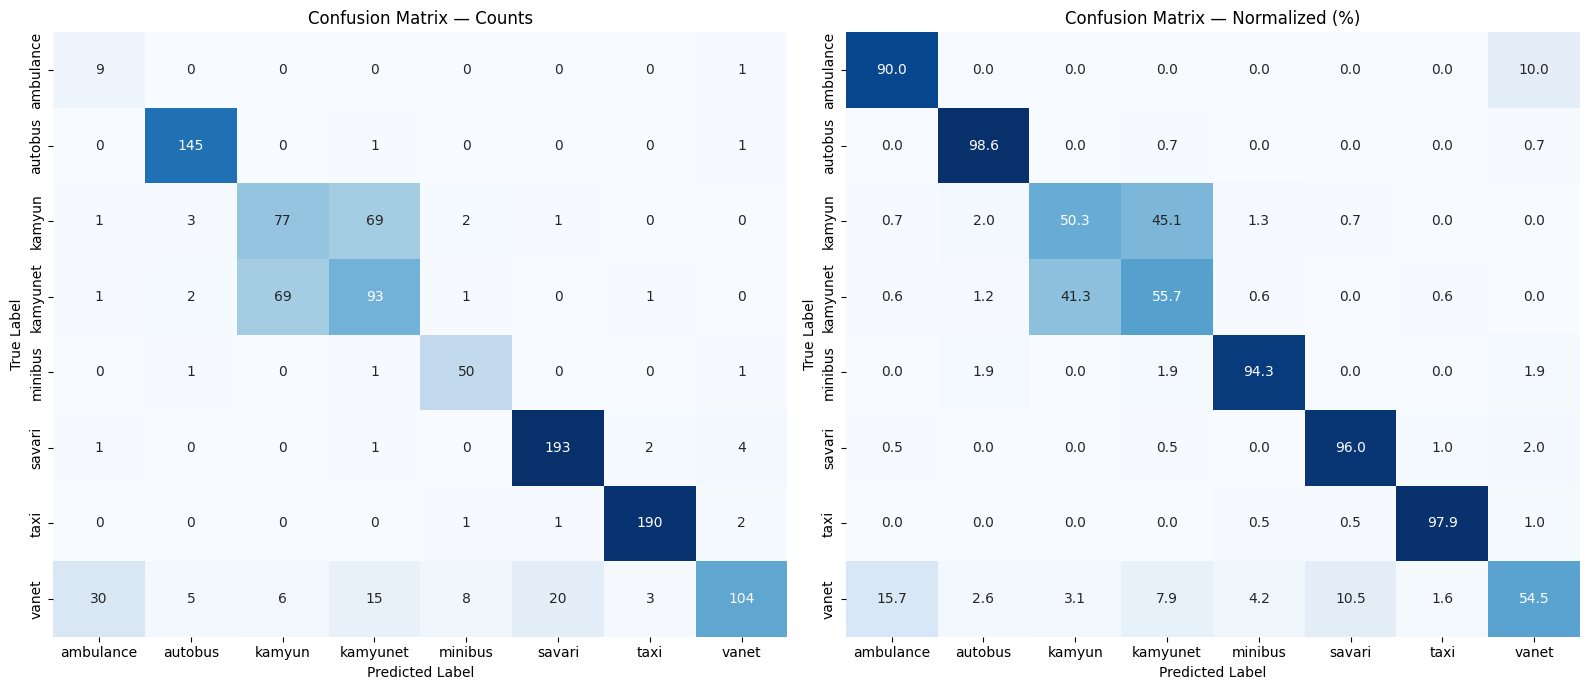

(array([[  9,   0,   0,   0,   0,   0,   0,   1],
        [  0, 145,   0,   1,   0,   0,   0,   1],
        [  1,   3,  77,  69,   2,   1,   0,   0],
        [  1,   2,  69,  93,   1,   0,   1,   0],
        [  0,   1,   0,   1,  50,   0,   0,   1],
        [  1,   0,   0,   1,   0, 193,   2,   4],
        [  0,   0,   0,   0,   1,   1, 190,   2],
        [ 30,   5,   6,  15,   8,  20,   3, 104]]),
 array([[         90,           0,           0,           0,           0,           0,           0,          10],
        [          0,      98.639,           0,     0.68027,           0,           0,           0,     0.68027],
        [    0.65359,      1.9608,      50.327,      45.098,      1.3072,     0.65359,           0,           0],
        [     0.5988,      1.1976,      41.317,      55.689,      0.5988,           0,      0.5988,           0],
        [          0,      1.8868,           0,      1.8868,       94.34,           0,           0,      1.8868],
        [    0.49751,       

In [33]:
plot_confusion_matrices(
    best_xception_model,
    'models/ best_xception_model.pth',
    test4,
    test4.dataset.classes,
    device,
)

In [8]:
# plot_misclassified_images(
#     model=best_xception_model,
#     weights_path="models/ best_xception_model.pth",
#     dataloader=test4,
#     class_names=test4.dataset.classes,
#     num_images=11,
# )

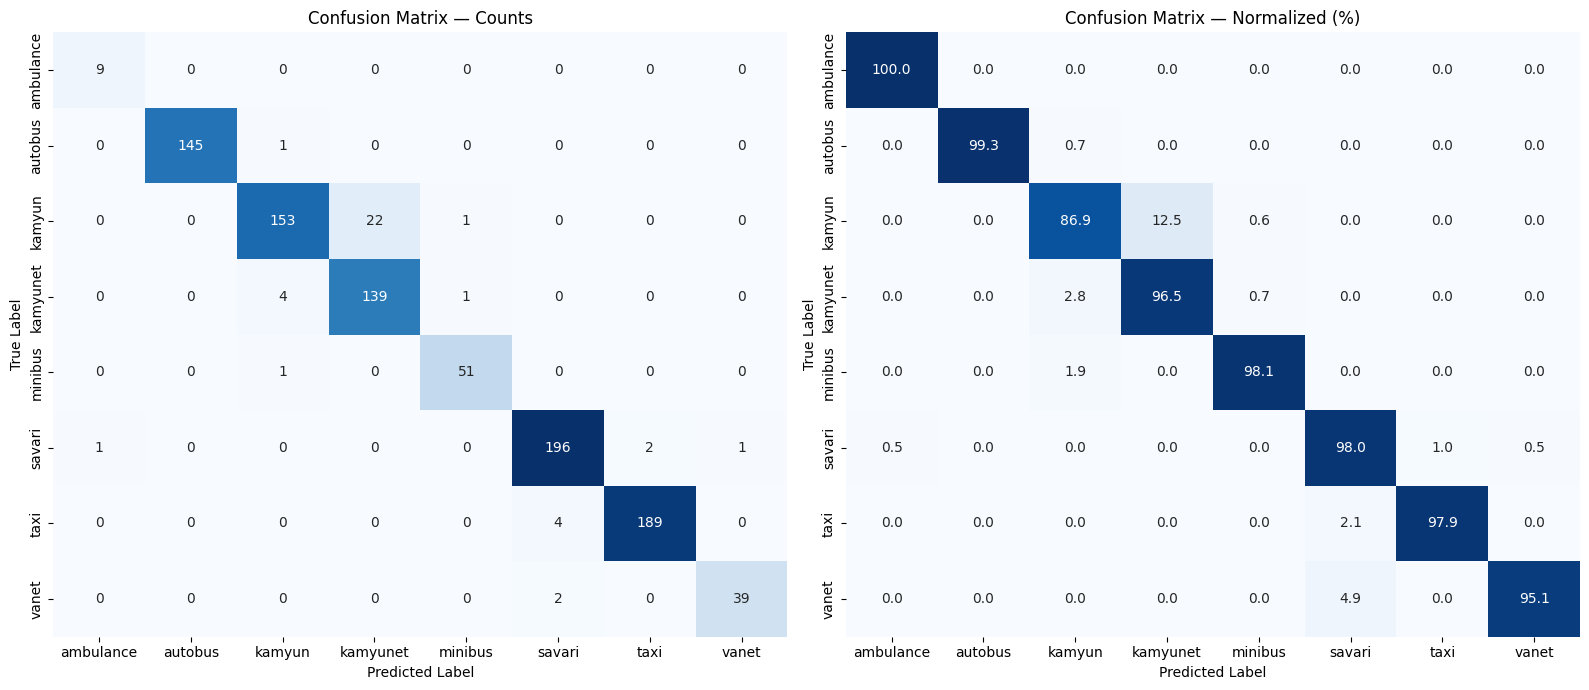

(array([[  9,   0,   0,   0,   0,   0,   0,   0],
        [  0, 145,   1,   0,   0,   0,   0,   0],
        [  0,   0, 153,  22,   1,   0,   0,   0],
        [  0,   0,   4, 139,   1,   0,   0,   0],
        [  0,   0,   1,   0,  51,   0,   0,   0],
        [  1,   0,   0,   0,   0, 196,   2,   1],
        [  0,   0,   0,   0,   0,   4, 189,   0],
        [  0,   0,   0,   0,   0,   2,   0,  39]]),
 array([[        100,           0,           0,           0,           0,           0,           0,           0],
        [          0,      99.315,     0.68493,           0,           0,           0,           0,           0],
        [          0,           0,      86.932,        12.5,     0.56818,           0,           0,           0],
        [          0,           0,      2.7778,      96.528,     0.69444,           0,           0,           0],
        [          0,           0,      1.9231,           0,      98.077,           0,           0,           0],
        [        0.5,       

In [34]:
plot_confusion_matrices(
    vgg,
    'models/vgg.pth',
    test0,
    test0.dataset.classes,
    device,
)

In [9]:
# plot_misclassified_images(
#     model=vgg,
#     weights_path="models/vgg.pth",
#     dataloader=test0,
#     class_names=test0.dataset.classes,
#     num_images=11,
# )

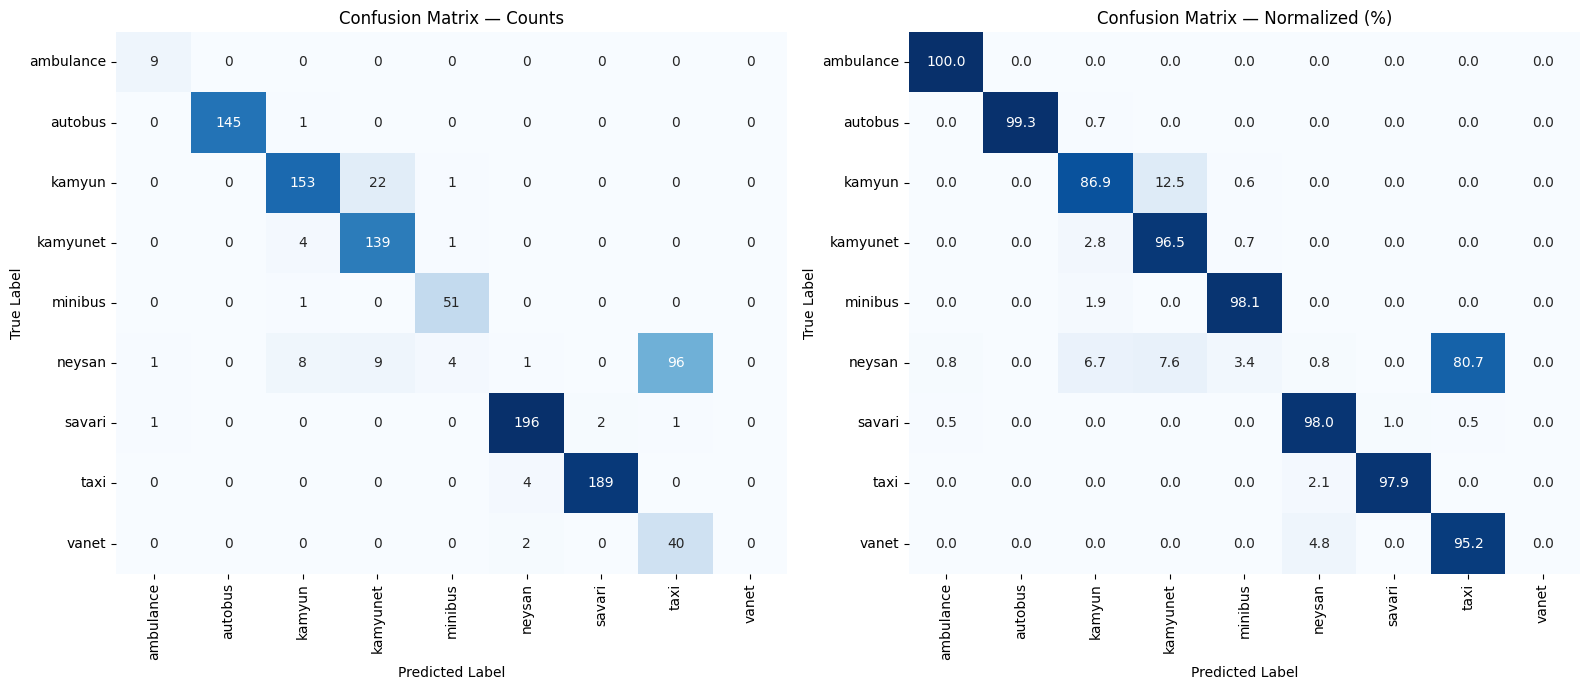

(array([[  9,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0, 145,   1,   0,   0,   0,   0,   0,   0],
        [  0,   0, 153,  22,   1,   0,   0,   0,   0],
        [  0,   0,   4, 139,   1,   0,   0,   0,   0],
        [  0,   0,   1,   0,  51,   0,   0,   0,   0],
        [  1,   0,   8,   9,   4,   1,   0,  96,   0],
        [  1,   0,   0,   0,   0, 196,   2,   1,   0],
        [  0,   0,   0,   0,   0,   4, 189,   0,   0],
        [  0,   0,   0,   0,   0,   2,   0,  40,   0]]),
 array([[        100,           0,           0,           0,           0,           0,           0,           0,           0],
        [          0,      99.315,     0.68493,           0,           0,           0,           0,           0,           0],
        [          0,           0,      86.932,        12.5,     0.56818,           0,           0,           0,           0],
        [          0,           0,      2.7778,      96.528,     0.69444,           0,           0,           0,          

In [41]:
plot_confusion_matrices(
    vgg,
    'models/vgg.pth',
    test1,
    test1.dataset.classes,
    device,
)

In [10]:
# plot_misclassified_images(
#     model=vgg,
#     weights_path="models/vgg.pth",
#     dataloader=test1,
#     class_names=test1.dataset.classes,
#     num_images=11,
# )

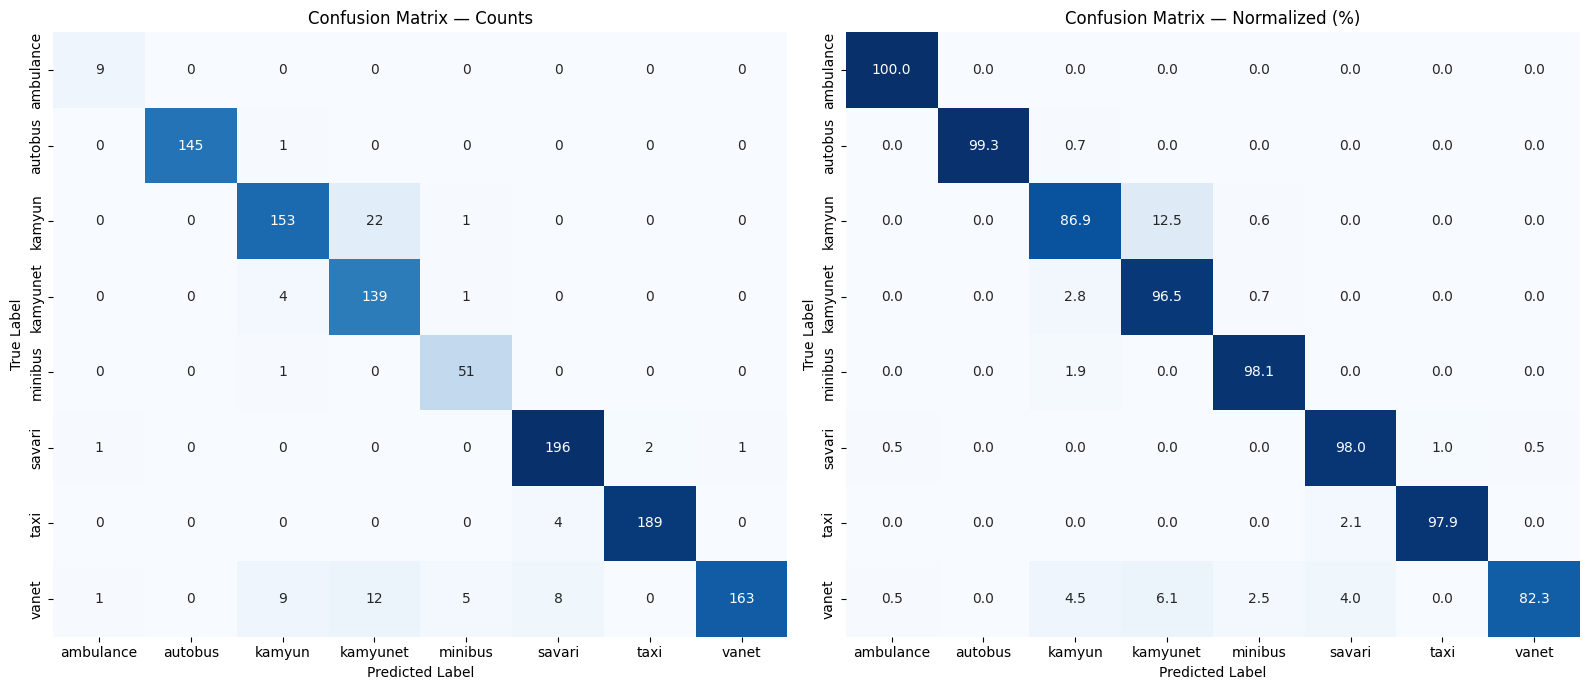

(array([[  9,   0,   0,   0,   0,   0,   0,   0],
        [  0, 145,   1,   0,   0,   0,   0,   0],
        [  0,   0, 153,  22,   1,   0,   0,   0],
        [  0,   0,   4, 139,   1,   0,   0,   0],
        [  0,   0,   1,   0,  51,   0,   0,   0],
        [  1,   0,   0,   0,   0, 196,   2,   1],
        [  0,   0,   0,   0,   0,   4, 189,   0],
        [  1,   0,   9,  12,   5,   8,   0, 163]]),
 array([[        100,           0,           0,           0,           0,           0,           0,           0],
        [          0,      99.315,     0.68493,           0,           0,           0,           0,           0],
        [          0,           0,      86.932,        12.5,     0.56818,           0,           0,           0],
        [          0,           0,      2.7778,      96.528,     0.69444,           0,           0,           0],
        [          0,           0,      1.9231,           0,      98.077,           0,           0,           0],
        [        0.5,       

In [40]:
plot_confusion_matrices(
    vgg,
    'models/vgg.pth',
    test2,
    test2.dataset.classes,
    device,
)

In [11]:
# plot_misclassified_images(
#     model=vgg,
#     weights_path="models/vgg.pth",
#     dataloader=test2,
#     class_names=test2.dataset.classes,
#     num_images=11,
# )

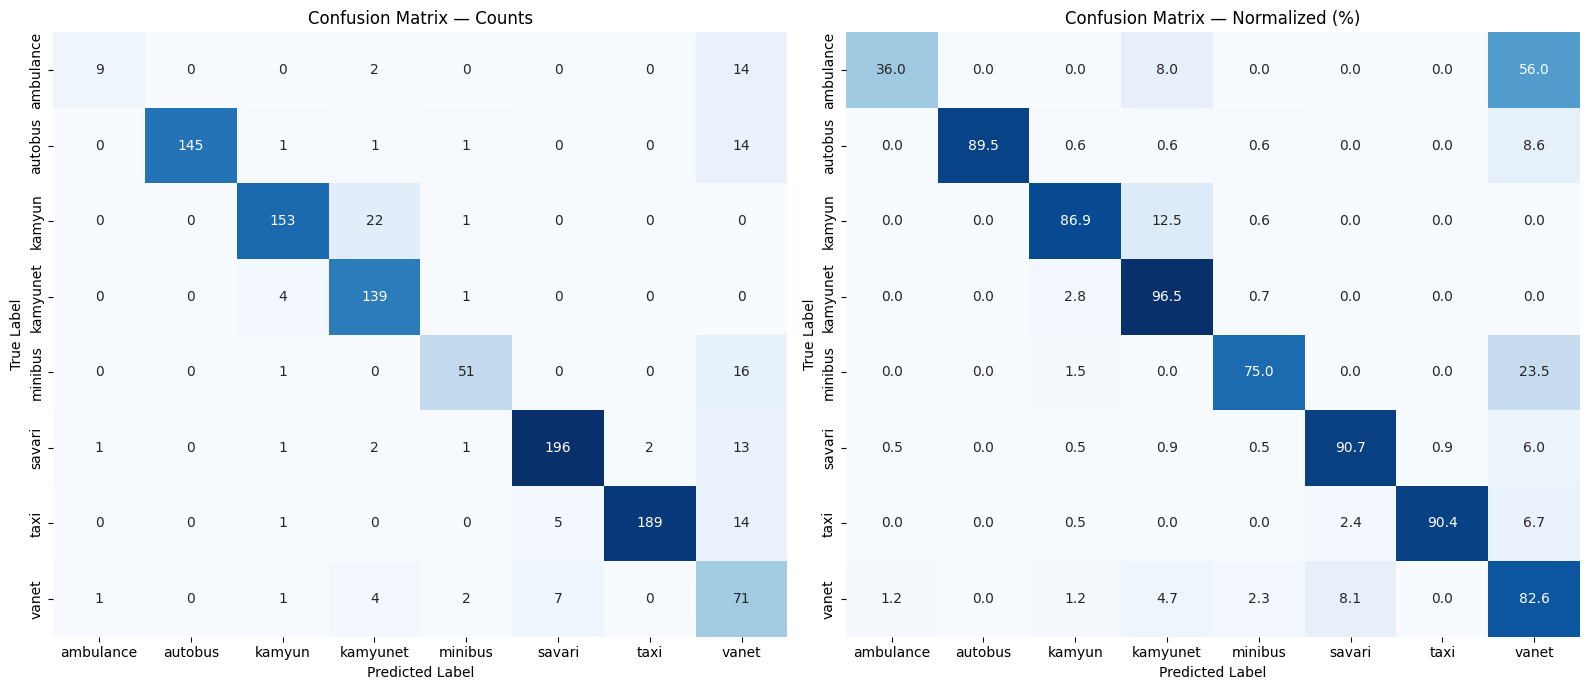

(array([[  9,   0,   0,   2,   0,   0,   0,  14],
        [  0, 145,   1,   1,   1,   0,   0,  14],
        [  0,   0, 153,  22,   1,   0,   0,   0],
        [  0,   0,   4, 139,   1,   0,   0,   0],
        [  0,   0,   1,   0,  51,   0,   0,  16],
        [  1,   0,   1,   2,   1, 196,   2,  13],
        [  0,   0,   1,   0,   0,   5, 189,  14],
        [  1,   0,   1,   4,   2,   7,   0,  71]]),
 array([[         36,           0,           0,           8,           0,           0,           0,          56],
        [          0,      89.506,     0.61728,     0.61728,     0.61728,           0,           0,       8.642],
        [          0,           0,      86.932,        12.5,     0.56818,           0,           0,           0],
        [          0,           0,      2.7778,      96.528,     0.69444,           0,           0,           0],
        [          0,           0,      1.4706,           0,          75,           0,           0,      23.529],
        [    0.46296,       

In [39]:
plot_confusion_matrices(
    vgg,
    'models/vgg.pth',
    test3,
    test3.dataset.classes,
    device,
)

In [12]:
# plot_misclassified_images(
#     model=vgg,
#     weights_path="models/vgg.pth",
#     dataloader=test3,
#     class_names=test3.dataset.classes,
#     num_images=11,
# )

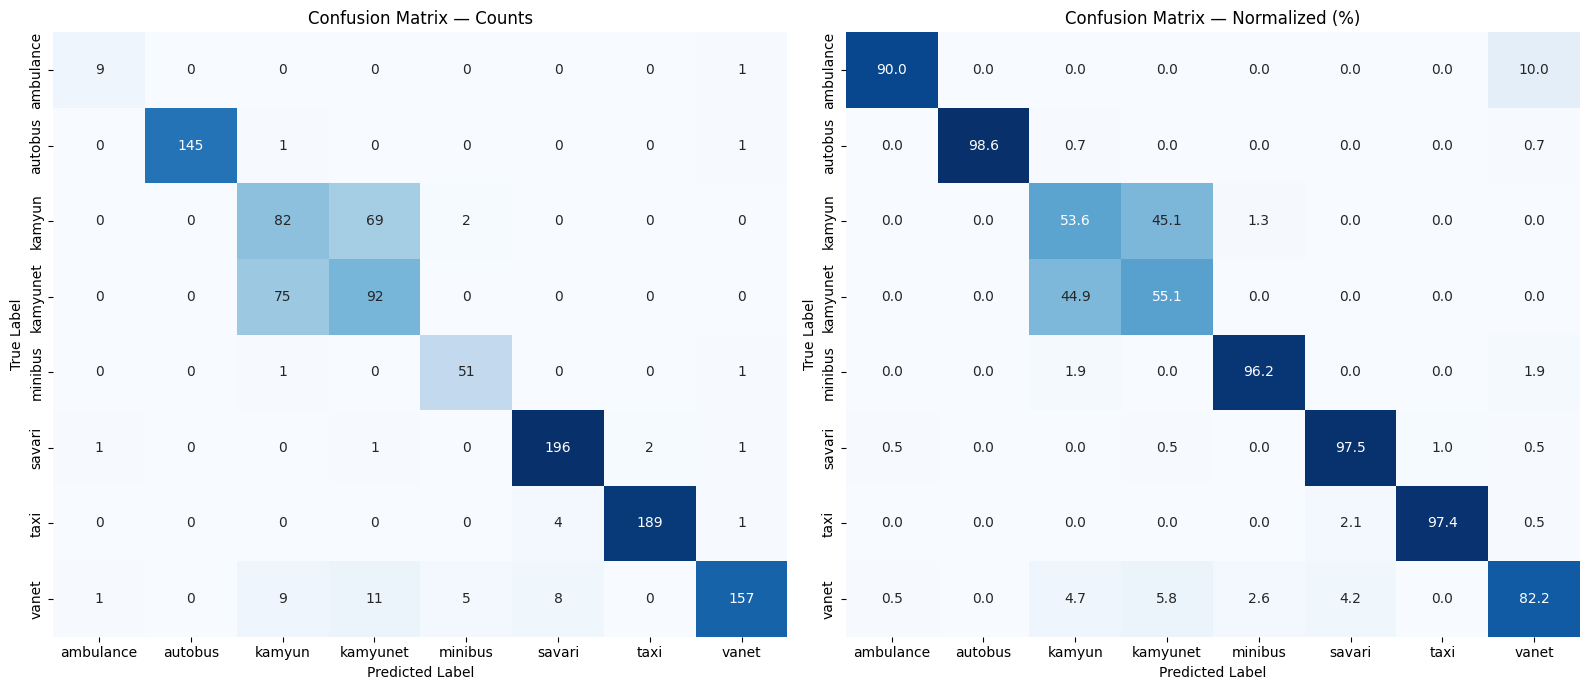

(array([[  9,   0,   0,   0,   0,   0,   0,   1],
        [  0, 145,   1,   0,   0,   0,   0,   1],
        [  0,   0,  82,  69,   2,   0,   0,   0],
        [  0,   0,  75,  92,   0,   0,   0,   0],
        [  0,   0,   1,   0,  51,   0,   0,   1],
        [  1,   0,   0,   1,   0, 196,   2,   1],
        [  0,   0,   0,   0,   0,   4, 189,   1],
        [  1,   0,   9,  11,   5,   8,   0, 157]]),
 array([[         90,           0,           0,           0,           0,           0,           0,          10],
        [          0,      98.639,     0.68027,           0,           0,           0,           0,     0.68027],
        [          0,           0,      53.595,      45.098,      1.3072,           0,           0,           0],
        [          0,           0,       44.91,       55.09,           0,           0,           0,           0],
        [          0,           0,      1.8868,           0,      96.226,           0,           0,      1.8868],
        [    0.49751,       

In [42]:
plot_confusion_matrices(
    vgg,
    'models/vgg.pth',
    test4,
    test4.dataset.classes,
    device,
)

In [13]:
# plot_misclassified_images(
#     model=vgg,
#     weights_path="models/vgg.pth",
#     dataloader=test4,
#     class_names=test4.dataset.classes,
#     num_images=11,
# )

In [13]:
train_feats_xc, train_logits_xc, train_labels_xc = extract_features(
    train_loader,
    best_xception_model,
    device
)

# train_feats_vgg, train_logits_vgg, train_labels_vgg = extract_features(
#     train_loader,
#     vgg,
#     device
# )

In [15]:
mahalanobis_stats_xc = fit_mahalanobis(
    train_feats_xc,
    train_labels_xc,
    num_classes=8,
    pca_dim=64
)

# mahalanobis_stats_vgg = fit_mahalanobis(
#     train_feats_vgg,
#     train_labels_vgg,
#     num_classes=8,
#     pca_dim=64
# )

2026-10-08 19:16:54 | INFO     | src.utils.ood | Original feature dimension: 512
2026-10-08 19:16:54 | INFO     | src.utils.ood | PCA feature dimension: 64
2026-10-08 19:16:54 | INFO     | src.utils.ood | Explained variance: 0.9883


In [17]:
temperature_xc = fit_temperature(
    best_xception_model,
    valid_loader,
    device
)

# temperature_vgg = fit_temperature(
#     vgg,
#     valid_loader,
#     device
# )

2026-10-08 19:17:23 | INFO     | src.utils.ood | Temperature: 1.7230


In [18]:
id_feats_xc, id_logits_xc, id_labels_xc = extract_features(
    valid_loader,
    best_xception_model,
    device
)

# id_feats_vgg, id_logits_vgg, id_labels_vgg = extract_features(
#     valid_loader,
#     vgg,
#     device
# )

In [19]:
xception_temperature = fit_temperature(best_xception_model, valid_loader, device)
print(f"Calibrated xception temperature: {xception_temperature:.3f}")

#vgg_temperature = fit_temperature(vgg, valid_loader, device)
#print(f"Calibrated vgg temperature: {vgg_temperature:.3f}")

2026-10-08 19:17:35 | INFO     | src.utils.ood | Temperature: 1.7230


Calibrated xception temperature: 1.723


In [20]:
ood_feats_xc, ood_logits_xc, ood_labels_xc = extract_features(
    ood_loader,
    best_xception_model,
    device
)

# ood_feats_vgg, ood_logits_vgg, ood_labels_vgg = extract_features(
#     ood_loader,
#     vgg,
#     device
# )

In [21]:
thresholds_xc = fit_ood_thresholds(
    id_features=id_feats_xc,
    id_logits=id_logits_xc,

    ood_features=ood_feats_xc,
    ood_logits=ood_logits_xc,

    mahalanobis_stats=mahalanobis_stats_xc,

    temperature=temperature_xc
)

# thresholds_vgg = fit_ood_thresholds(
#     id_features=id_feats_vgg,
#     id_logits=id_logits_vgg,

#     ood_features=ood_feats_vgg,
#     ood_logits=ood_logits_vgg,

#     mahalanobis_stats=mahalanobis_stats_vgg,

#     temperature=temperature_vgg
# )

In [22]:
checkpoint = {
    "model_state": best_xception_model.state_dict(),

    "temperature": temperature_xc,

    "pca": mahalanobis_stats_xc["pca"],

    "centroids":
        mahalanobis_stats_xc["centroids"],

    "covariance":
        mahalanobis_stats_xc["covariance"],

    "cov_inv":
        mahalanobis_stats_xc["cov_inv"],

    "dist_threshold":
        thresholds_xc["dist_threshold"],

    "conf_threshold":
        thresholds_xc["confidence_threshold"],
     "class_names": classes,
}


torch.save(
    checkpoint,
    "models/final_model_xc.pt"
)

In [16]:
checkpoint = {
    "model_state": vgg.state_dict(),

    "temperature": temperature_vgg,

    "pca": mahalanobis_stats_vgg["pca"],

    "centroids":
        mahalanobis_stats_vgg["centroids"],

    "covariance":
        mahalanobis_stats_vgg["covariance"],

    "cov_inv":
        mahalanobis_stats_vgg["cov_inv"],

    "dist_threshold":
        thresholds_vgg["dist_threshold"],

    "conf_threshold":
        thresholds_vgg["confidence_threshold"],
     "class_names": classes,
}


torch.save(
    checkpoint,
    "models/final_model_vgg.pt"
)

In [23]:
model, ckpt = load_checkpoint(
    best_xception_model,
    "models/final_model_xc.pt",
    device
)

image_path = "data/test/ambulance/213375240.jpg"
result = predict(
    image_path,
    best_xception_model,
    ckpt,
    device
)
print(result)

{'label': 'unknown', 'softmax_conf': 0.9999688863754272, 'mahalanobis_dist': 57.427513122558594, 'mahalanobis_class': 'ambulance', 'raw_pred_class': 'ambulance', 'distance_unknown': True, 'confidence_unknown': False}


In [31]:
print("\nThreshold")
print("distance threshold:", thresholds_xc["dist_threshold"])

# OOD scores
ood_distances, ood_confidences = calculate_ood_scores(
    ood_feats_xc,
    ood_logits_xc,
    mahalanobis_stats_xc,
    temperature_xc
)

print("\nOOD Mahalanobis distances")
print("min    :", ood_distances.min())
print("mean   :", ood_distances.mean())
print("median :", np.median(ood_distances))
print("95%    :", np.percentile(ood_distances, 95))
print("99%    :", np.percentile(ood_distances, 99))
print("max    :", ood_distances.max())


# ID scores
id_distances, id_confidences = calculate_ood_scores(
    id_feats_xc,
    id_logits_xc,
    mahalanobis_stats_xc,
    temperature_xc
)

print("\nID Mahalanobis distances")
print("min    :", id_distances.min())
print("mean   :", id_distances.mean())
print("median :", np.median(id_distances))
print("95%    :", np.percentile(id_distances, 95))
print("99%    :", np.percentile(id_distances, 99))
print("max    :", id_distances.max())


# Threshold
print("\nThreshold")
print("distance threshold:", thresholds_xc["dist_threshold"])


Threshold
distance threshold: 48.43218231201172

OOD Mahalanobis distances
min    : 31.658031
mean   : 65.2339
median : 62.756355
95%    : 95.60771
99%    : 119.798546
max    : 153.08868

ID Mahalanobis distances
min    : 16.619997
mean   : 70.246704
median : 63.597176
95%    : 126.68377
99%    : 173.71585
max    : 202.7631

Threshold
distance threshold: 48.43218231201172


In [18]:
xception_feat, xception_train_labels = extract_features(train_loader, best_xception_model, device)
vgg_feat, vgg_train_labels = extract_features(train_loader, vgg, device)

In [19]:
xception_centroids, xception_cov_inv = \
        calc_centroids_cov_inv(xception_feat, xception_train_labels, num_classes=8)

vgg_centroids, vgg_cov_inv = \
        calc_centroids_cov_inv(vgg_feat, vgg_train_labels, num_classes=8)

In [87]:
UNKNOWN_LABEL = "unknown"
SOFTMAX_CONF_THRESHOLD_xc = 0.60  # tune on your own held-out set
SOFTMAX_CONF_THRESHOLD_vgg = 0.13  # tune on your own held-out set
DIST_PERCENTILE = 95.5  # how strict the distance gate is

In [88]:
xception_val_feats, _ = extract_features(valid_loader, best_xception_model, device)
xception_val_dists = np.array([mahalanobis_min_distance(f, xception_centroids, xception_cov_inv)[0] for f in xception_val_feats])
XCEPTION_DIST_THRESHOLD = np.percentile(xception_val_dists, DIST_PERCENTILE)
print(
    f"Mahalanobis distance threshold ({DIST_PERCENTILE}th pct of val): {XCEPTION_DIST_THRESHOLD:.2f}"
)

Mahalanobis distance threshold (95.5th pct of val): 1685.46


In [89]:
vgg_val_feats, _ = extract_features(valid_loader, vgg, device)
vgg_val_dists = np.array([mahalanobis_min_distance(f, vgg_centroids, vgg_cov_inv)[0] for f in vgg_val_feats])
VGG_DIST_THRESHOLD = np.percentile(vgg_val_dists, DIST_PERCENTILE)
print(
    f"Mahalanobis distance threshold ({DIST_PERCENTILE}th pct of val): {VGG_DIST_THRESHOLD:.2f}"
)

Mahalanobis distance threshold (95.5th pct of val): 2815883.45


In [90]:
torch.save(
    {
        "model_state": best_xception_model.state_dict(),
        "class_names": valid_loader.dataset.classes,
        "temperature": xception_temperature,
        "centroids": xception_centroids,
        "cov_inv": xception_cov_inv,
        "dist_threshold": XCEPTION_DIST_THRESHOLD,
        "conf_threshold": SOFTMAX_CONF_THRESHOLD_xc,
    },
    "open_set_data/xception_open_set.pt",
)

print("Saved model + open-set calibration to open_set_data/xception_open_set.pt")

Saved model + open-set calibration to open_set_data/xception_open_set.pt


In [91]:
torch.save(
    {
        "model_state": vgg.state_dict(),
        "class_names": valid_loader.dataset.classes,
        "temperature": vgg_temperature,
        "centroids": vgg_centroids,
        "cov_inv": vgg_cov_inv,
        "dist_threshold": VGG_DIST_THRESHOLD,
        "conf_threshold": SOFTMAX_CONF_THRESHOLD_vgg,
    },
    "open_set_data/vgg_open_set.pt",
)

print("Saved model + open-set calibration to open_set_data/vgg_open_set.pt")

Saved model + open-set calibration to open_set_data/vgg_open_set.pt


# Predict

In [83]:
xception_model = create_model('small-xception1', 8).to(device)
xception_model, xception_ckpt = \
                        load_checkpoint(xception_model, 
                                "open_set_data/xception_open_set.pt",
                                device)

result = predict("data/test-neysan/195003645.jpg", xception_model, xception_ckpt, device)
print(result)

{'label': 'unknown', 'softmax_conf': 0.5248575806617737, 'mahalanobis_dist': 725.1202859901508, 'raw_pred_class': 'vanet'}


In [84]:
xception_model = create_model('small-xception1', 8).to(device)
xception_model, xception_ckpt = \
                        load_checkpoint(xception_model, 
                                "open_set_data/xception_open_set.pt",
                                device)

result = predict("data/test/ambulance/197398569.jpg", xception_model, xception_ckpt, device)
print(result)

{'label': 'unknown', 'softmax_conf': 0.6483889222145081, 'mahalanobis_dist': 677.6540723898942, 'raw_pred_class': 'ambulance'}


In [85]:
vgg_model = create_model('vgg', 8).to(device)
vgg_model, vgg_ckpt = \
                        load_checkpoint(vgg_model, 
                                "open_set_data/vgg_open_set.pt",
                                device)

result = predict("data/test-neysan/195003645.jpg", vgg_model, vgg_ckpt, device)
print(result)

{'label': 'autobus', 'softmax_conf': 0.136224627494812, 'mahalanobis_dist': 1868688.390640252, 'raw_pred_class': 'autobus'}


In [86]:
vgg_model = create_model('vgg', 8).to(device)
vgg_model, vgg_ckpt = \
                        load_checkpoint(vgg_model, 
                                "open_set_data/vgg_open_set.pt",
                                device)

result = predict("data/test/ambulance/213375240.jpg", vgg_model, vgg_ckpt, device)
print(result)

{'label': 'vanet', 'softmax_conf': 0.13202916085720062, 'mahalanobis_dist': 530294.1402907186, 'raw_pred_class': 'vanet'}
